# Segmentasi Parasit Malaria pada MP-IDB dengan Pengolahan Citra Klasik

Notebook ini adalah revisi yang mengikuti dokumen utama `docs/report-progress1.md`.

**Ruang lingkup tahap ini**
- Spesies: *Plasmodium falciparum* dan *Plasmodium vivax*, seluruh stadium
  (ring, trophozoite, schizont, gametocyte).
- Subset **stratified**: 2 citra per (spesies, stadium) per split -> **16 citra
  tuning** dan **16 citra uji** (total 32 citra).
- Citra diperkecil **50%** (`INTER_AREA`), mask dan label instance memakai `INTER_NEAREST`.
- Eksperimen A: Otsu multi-level, adaptive threshold, k-means, dan **pixel-if-else sebagai metode tambahan**.
- `pixel-if-else` dan `object-level if-else` dipertahankan sebagai temuan; object-level baru dijalankan pada Eksperimen C.
- Eksperimen B (pengaruh preprocessing) dan Eksperimen C (morfologi pasca-segmentasi) **sudah dijalankan**.

**Catatan metodologis**
- Pemilihan kanal dan tuning threshold hanya memakai 16 citra tuning.
- 16 citra uji tidak dipakai untuk memilih parameter apa pun.
- Semua metode pada Eksperimen A memakai cleanup minimal yang sama.
- Citra yang punya lebih dari satu tag stadium dipetakan ke **tepat satu** stadium
  dengan aturan deterministik (lihat Bagian 1).

**Catatan data**
- Dataset MP-IDB: 210 citra; falciparum 103 citra, vivax 40 citra.
- Berkas citra pada salinan Dataset Ninja ini berupa JPG; anotasi disimpan sebagai
  bitmap 1-bit yang dikompresi di dalam JSON.

In [1]:
from pathlib import Path
import json, base64, zlib, io, random, time, warnings

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

from skimage.filters import threshold_multiotsu
from skimage.measure import label
from skimage.morphology import remove_small_objects

warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)


def find_project_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'mp-idb-DatasetNinja').is_dir():
            return cand
    raise FileNotFoundError(
        'Folder mp-idb-DatasetNinja tidak ditemukan. Jalankan notebook dari root proyek.'
    )


PROJECT_ROOT = find_project_root()
DATASET_ROOT = PROJECT_ROOT / 'mp-idb-DatasetNinja'
IMG_DIR = DATASET_ROOT / 'ds' / 'img'
ANN_DIR = DATASET_ROOT / 'ds' / 'ann'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'progress1'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
SCALE = 0.5
# Cleanup minimal disesuaikan dengan skala: 50 px pada resolusi penuh -> ~12 px pada 50%.
MIN_AREA = max(10, int(round(50 * SCALE ** 2)))
OBJECT_IOU_THR = 0.10
# K-means OpenCV memakai RNG internal; kunci agar hasil dapat direproduksi.
cv2.setRNGSeed(SEED)

print('Project root :', PROJECT_ROOT)
print('Image dir    :', IMG_DIR)
print('Annotation   :', ANN_DIR)
print('Results dir  :', RESULTS_DIR)
print('OpenCV       :', cv2.__version__)
print('scikit-image :', __import__('skimage').__version__)
print('Seed / scale :', SEED, '/', SCALE)
print('Min area     :', MIN_AREA, 'px (50% scale)')

Project root : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project
Image dir    : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/mp-idb-DatasetNinja/ds/img
Annotation   : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/mp-idb-DatasetNinja/ds/ann
Results dir  : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/results/progress1
OpenCV       : 5.0.0
scikit-image : 0.26.0
Seed / scale : 42 / 0.5
Min area     : 12 px (50% scale)


## 1. Inventaris dataset dan seleksi 32 citra (falciparum + vivax)

Anotasi MP-IDB menyimpan mask sebagai bitmap 1-bit yang dikompresi `zlib` lalu `base64`.
Setiap objek punya `origin` `(x, y)`; mask ditempatkan pada koordinat tersebut.

Kriteria seleksi:
1. Semua objek pada citra berkelas tunggal `falciparum` atau `vivax` (tidak ada kelas campuran).
2. Citra memiliki setidaknya satu objek.
3. Subset **stratified**: 2 citra per (spesies, stadium) untuk tuning dan 2 untuk uji,
   sehingga total 16 + 16 = 32 citra.

**Penanganan citra multi-stadium.** Banyak citra MP-IDB memiliki beberapa tag stadium
(mis. `ring` + `trophozoite`). Agar setiap citra menempati satu sel saja, stadium
diisi dari yang kandidatnya paling sedikit (gametocyte -> trophozoite -> schizont -> ring);
pada tiap stadium dipilih citra yang paling eksklusif. Aturan ini deterministik dengan
seed tetap, dan menghasilkan 4 citra per (spesies, stadium) (2 tuning + 2 uji).

In [2]:
def annotation_info(ann_path):
    '''Baca metadata anotasi tanpa menyimpan mask resolusi penuh.'''
    d = json.loads(Path(ann_path).read_text())
    h = int(d['size']['height'])
    w = int(d['size']['width'])
    stages = sorted({
        str(t.get('name', '')).lower().replace(' stage', '').strip()
        for t in d.get('tags', [])
        if 'stage' in str(t.get('name', '')).lower()
    })

    objects = []
    for i, obj in enumerate(d.get('objects', []), start=1):
        png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
        m = np.array(Image.open(io.BytesIO(png)).convert('1'), dtype=np.uint8) > 0
        x, y = map(int, obj['bitmap']['origin'])
        mh, mw = m.shape
        mh = min(mh, h - y)
        mw = min(mw, w - x)
        if mh <= 0 or mw <= 0:
            continue
        mm = m[:mh, :mw]
        objects.append({
            'label': i,
            'area': int(mm.sum()),
            'bbox': (y, x, y + mh, x + mw),
            'classTitle': str(obj.get('classTitle', '')).lower().strip(),
        })

    return {
        'image_id': Path(ann_path).name[:-5],  # remove .json
        'height': h,
        'width': w,
        'stages': stages,
        'objects': objects,
    }


SPECIES = ['falciparum', 'vivax']
STAGES = ['ring', 'trophozoite', 'schizont', 'gametocyte']
N_PER_STAGE_PER_SPLIT = 2
N_PER_GROUP = 2 * N_PER_STAGE_PER_SPLIT  # 4 citra per (spesies, stadium)


def build_inventory(species_list=SPECIES):
    rows = []
    for ann_path in sorted(ANN_DIR.glob('*.json')):
        info = annotation_info(ann_path)
        classes = {o['classTitle'] for o in info['objects']}
        if len(classes) != 1 or len(info['objects']) == 0:
            continue
        sp = next(iter(classes))
        if sp not in species_list:
            continue
        rows.append({
            'image_id': info['image_id'],
            'species': sp,
            'stages': info['stages'],
            'n_objects': len(info['objects']),
            'areas': [o['area'] for o in info['objects']],
            'total_area': int(sum(o['area'] for o in info['objects'])),
            'width': info['width'],
            'height': info['height'],
            'image_path': str(IMG_DIR / info['image_id']),
            'ann_path': str(ann_path),
        })
    return pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)


def assign_primary_stage(df, seed=SEED):
    '''Petakan setiap citra ke TEPAT SATU stadium (greedy scarcest-first).

    Stadium dengan kandidat paling sedikit diisi lebih dulu; pada tiap stadium
    dipilih citra yang paling eksklusif (paling sedikit stadium lain yang belum
    terisi). Deterministik sehingga hasil dapat direproduksi.
    '''
    tags = {row['image_id']: set(row['stages']) for _, row in df.iterrows()}
    nobj = {row['image_id']: int(row['n_objects']) for _, row in df.iterrows()}
    assigned = {}
    for sp in sorted(df['species'].unique()):
        ids = set(df.loc[df['species'] == sp, 'image_id'])
        cand = {st: {i for i in ids if st in tags[i]} for st in STAGES}
        order = sorted(STAGES, key=lambda st: (len(cand[st]), STAGES.index(st)))
        filled = set()
        for st in order:
            avail = [i for i in cand[st] if i not in assigned]

            def key(i, st=st, filled=filled):
                pending = [o for o in STAGES
                           if o != st and o not in filled and i in cand[o]]
                return (len(pending), -nobj[i], i)

            avail.sort(key=key)
            pick = avail[:N_PER_GROUP]
            if len(pick) < N_PER_GROUP:
                raise ValueError(
                    f'Kandidat {sp}/{st} hanya {len(pick)}, butuh {N_PER_GROUP}.')
            for i in pick:
                assigned[i] = st
            filled.add(st)
    return assigned


def select_splits(df, assigned, seed=SEED):
    out = df.copy()
    out['stage'] = out['image_id'].map(assigned)
    out = out[out['stage'].notna()].copy()
    rng = random.Random(seed)
    split = {}
    for _, grp in out.groupby(['species', 'stage'], sort=True):
        ids = sorted(grp['image_id'].tolist())
        rng.shuffle(ids)
        if len(ids) < N_PER_GROUP:
            raise ValueError(
                f'Grup {grp.iloc[0]["species"]}/{grp.iloc[0]["stage"]} hanya {len(ids)} citra.')
        for i in ids[:N_PER_STAGE_PER_SPLIT]:
            split[i] = 'train'
        for i in ids[N_PER_STAGE_PER_SPLIT:N_PER_GROUP]:
            split[i] = 'test'
    out['split'] = out['image_id'].map(split)
    out = out[out['split'].notna()].copy()
    out['split'] = pd.Categorical(out['split'], categories=['train', 'test'], ordered=True)
    return out.sort_values(['split', 'species', 'stage', 'image_id']).reset_index(drop=True)


inventory = build_inventory()
primary_stage = assign_primary_stage(inventory, seed=SEED)
selected = select_splits(inventory, primary_stage, seed=SEED)

print('Spesies           :', ', '.join(SPECIES))
print('Citra kandidat    :', len(inventory),
      '(' + ', '.join(f'{s}: {int((inventory["species"]==s).sum())}' for s in SPECIES) + ')')
print('Citra terpilih    :', len(selected),
      f'({int((selected["split"]=="train").sum())} tuning + '
      f'{int((selected["split"]=="test").sum())} uji)')
print()
print('Komposisi subset terpilih (spesies x stadium x split):')
comp = (selected.groupby(['species', 'stage', 'split'], observed=True).size()
        .unstack('split', fill_value=0))
display(comp)
print()
print('Objek per citra (min/median/mean/max) pada subset:',
      int(selected['n_objects'].min()),
      float(selected['n_objects'].median()),
      round(float(selected['n_objects'].mean()), 2),
      int(selected['n_objects'].max()))
print()
print('Daftar 32 citra terpilih:')
display(selected[['image_id', 'species', 'stage', 'stages', 'split', 'n_objects']])

assert selected['image_id'].is_unique
assert len(selected) == len(SPECIES) * len(STAGES) * N_PER_GROUP

Spesies           : falciparum, vivax
Citra kandidat    : 143 (falciparum: 103, vivax: 40)
Citra terpilih    : 32 (16 tuning + 16 uji)

Komposisi subset terpilih (spesies x stadium x split):


split                   train  test
species    stage                   
falciparum gametocyte       2     2
           ring             2     2
           schizont         2     2
           trophozoite      2     2
vivax      gametocyte       2     2
           ring             2     2
           schizont         2     2
           trophozoite      2     2


Objek per citra (min/median/mean/max) pada subset: 1 1.5 8.75 67

Daftar 32 citra terpilih:


,image_id,species,stage,stages,split,n_objects
0,1603223711-0005-G.jpg,falciparum,gametocyte,[gametocyte],train,1
1,1603223711-0006-G.jpg,falciparum,gametocyte,[gametocyte],train,1
2,1701151546-0015-R_T.jpg,falciparum,ring,"[ring, trophozoite]",train,37
3,1704282807-0017-R.jpg,falciparum,ring,[ring],train,34
4,1305121398-0011-S.jpg,falciparum,schizont,[schizont],train,1
5,1305121398-0013-S.jpg,falciparum,schizont,[schizont],train,1
6,1409191647-0008-T.jpg,falciparum,trophozoite,[trophozoite],train,1
7,1603223711-0002-T_G.jpg,falciparum,trophozoite,"[gametocyte, trophozoite]",train,2
8,1703121298-0008-G.jpg,vivax,gametocyte,[gametocyte],train,1
9,1703121298-0010-G.jpg,vivax,gametocyte,[gametocyte],train,2


## 2. Memuat 32 citra pada skala 50%

GT biner dan label instance diperkecil dengan nearest-neighbor.
Jika ada label instance yang hilang setelah resize, notebook memberi peringatan agar bisa diperiksa.

In [3]:
def decode_annotation(ann_path):
    '''Decode semua objek menjadi GT biner dan label instance pada resolusi penuh.'''
    d = json.loads(Path(ann_path).read_text())
    h = int(d['size']['height'])
    w = int(d['size']['width'])
    gt = np.zeros((h, w), dtype=np.uint8)
    gt_labels = np.zeros((h, w), dtype=np.int32)
    objects = []

    for i, obj in enumerate(d.get('objects', []), start=1):
        png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
        m = np.array(Image.open(io.BytesIO(png)).convert('1'), dtype=np.uint8) > 0
        x, y = map(int, obj['bitmap']['origin'])
        mh, mw = m.shape
        mh = min(mh, h - y)
        mw = min(mw, w - x)
        if mh <= 0 or mw <= 0:
            continue
        m = m[:mh, :mw]
        gt[y:y + mh, x:x + mw] |= m.astype(np.uint8)
        sub = gt_labels[y:y + mh, x:x + mw]
        sub[m] = i
        objects.append({
            'label': i,
            'area': int(m.sum()),
            'bbox': (y, x, y + mh, x + mw),
            'classTitle': str(obj.get('classTitle', '')).lower().strip(),
        })

    return gt, gt_labels, objects


def load_record(row):
    bgr = cv2.imread(str(IMG_DIR / row['image_id']), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(IMG_DIR / row['image_id'])

    gt_full, labels_full, objects = decode_annotation(row['ann_path'])
    h, w = bgr.shape[:2]
    h2, w2 = int(round(h * SCALE)), int(round(w * SCALE))

    bgr_small = cv2.resize(bgr, (w2, h2), interpolation=cv2.INTER_AREA)
    gt_small = cv2.resize(gt_full, (w2, h2), interpolation=cv2.INTER_NEAREST) > 0
    labels_small = cv2.resize(labels_full, (w2, h2), interpolation=cv2.INTER_NEAREST)

    full_ids = set(np.unique(labels_full).tolist()) - {0}
    small_ids = set(np.unique(labels_small).tolist()) - {0}
    if full_ids != small_ids:
        print(f"  [warning] {row['image_id']}: label berubah setelah resize "
              f"({len(full_ids)} -> {len(small_ids)})")

    max_label = int(labels_small.max()) if labels_small.size else 0
    areas = np.bincount(labels_small.ravel(), minlength=max_label + 1).astype(int)
    object_areas = [int(areas[i]) for i in sorted(small_ids) if i < len(areas)]
    object_areas = [a for a in object_areas if a > 0]

    return {
        'image_id': row['image_id'],
        'species': row['species'],
        'split': str(row['split']),
        'stages': row['stages'],
        'stage': row.get('stage'),
        'bgr': bgr_small,
        'gt': gt_small,
        'gt_labels': labels_small,
        'shape': bgr_small.shape[:2],
        'n_objects': len(object_areas),
        'areas': object_areas,
        'total_area': int(sum(object_areas)),
    }


records = [load_record(row) for _, row in selected.iterrows()]
TRAIN = [r for r in records if r['split'] == 'train']
TEST = [r for r in records if r['split'] == 'test']

assert len(TRAIN) == 16, len(TRAIN)
assert len(TEST) == 16, len(TEST)
assert not ({r['image_id'] for r in TRAIN} & {r['image_id'] for r in TEST})

print('TRAIN:', len(TRAIN), '| TEST:', len(TEST))
print('Spesies train/test:',
      sorted({r['species'] for r in TRAIN}), '|', sorted({r['species'] for r in TEST}))
print('Jumlah objek GT  train/test:',
      sum(r['n_objects'] for r in TRAIN), '/', sum(r['n_objects'] for r in TEST))
print('Rata-rata objek/citra train/test:',
      round(np.mean([r['n_objects'] for r in TRAIN]), 2), '/',
      round(np.mean([r['n_objects'] for r in TEST]), 2))
print('Rata-rata fraksi piksel GT train/test:',
      f"{np.mean([r['gt'].mean() for r in TRAIN]):.5%}", '/',
      f"{np.mean([r['gt'].mean() for r in TEST]):.5%}")
print('Ukuran citra setelah resize:', records[0]['shape'])

print()
print('Jumlah objek GT per (spesies, stadium, split):')
meta = pd.DataFrame([{'species': r['species'], 'stage': r['stage'], 'split': r['split'],
                      'n_objects': r['n_objects']} for r in records])
display(meta.groupby(['species', 'stage', 'split'], observed=True)['n_objects']
        .sum().unstack('split', fill_value=0))


TRAIN: 16 | TEST: 16
Spesies train/test: ['falciparum', 'vivax'] | ['falciparum', 'vivax']
Jumlah objek GT  train/test: 94 / 186
Rata-rata objek/citra train/test: 5.88 / 11.62
Rata-rata fraksi piksel GT train/test: 0.51954% / 0.73609%
Ukuran citra setelah resize: (972, 1296)

Jumlah objek GT per (spesies, stadium, split):


split                   test  train
species    stage                   
falciparum gametocyte     42      2
           ring          109     71
           schizont        2      2
           trophozoite    16      3
vivax      gametocyte      5      3
           ring            7      6
           schizont        3      2
           trophozoite     2      5

## 3. Kanal warna dan preprocessing minimal

Kandidat kanal:
- `gray`, `green`, `L`, `a`, `b`, `S`, dan `P = a - b` (*purple score*).
- Median 3x3 diterapkan pada semua kanal, sesuai preprocessing minimal Eksperimen A.

Polaritas threshold ditetapkan dari sifat kanal:
- `gray`, `green`, `L`, `b`: parasit lebih gelap -> ambil kelas gelap.
- `a`, `S`, `P`: parasit lebih ungu/saturasi tinggi -> ambil kelas terang.

In [4]:
def percentile_norm(x, lo=1, hi=99):
    x = np.asarray(x, dtype=np.float32)
    p1, p2 = np.percentile(x, [lo, hi])
    if p2 <= p1:
        return np.zeros_like(x, dtype=np.float32)
    return np.clip((x - p1) / (p2 - p1), 0.0, 1.0)


def median3(x):
    return cv2.medianBlur(x, 3)


def build_channels(rec):
    lab = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    hsv = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2GRAY)
    green = rec['bgr'][:, :, 1]

    L, a, b, S, gray, green = [
        median3(x) for x in (L, a, b, hsv[:, :, 1], gray, green)
    ]
    P = a.astype(np.float32) - b.astype(np.float32)
    return {'gray': gray, 'green': green, 'L': L, 'a': a, 'b': b, 'S': S, 'P': P}


CHANNELS = ['gray', 'green', 'L', 'a', 'b', 'S', 'P']
CHANNEL_NAMES = {
    'gray': 'Grayscale', 'green': 'Green (RGB)', 'L': 'Lab L',
    'a': 'Lab a', 'b': 'Lab b', 'S': 'HSV S', 'P': 'Purple (a-b)',
}
CHANNEL_POLARITY = {
    'gray': 'dark', 'green': 'dark', 'L': 'dark', 'a': 'bright',
    'b': 'dark', 'S': 'bright', 'P': 'bright',
}


def channel_uint8(ch, name):
    if name == 'P':
        return (percentile_norm(ch) * 255.0).clip(0, 255).astype(np.uint8)
    return ch


print('Kanal yang diuji:', CHANNELS)
print('Polaritas:', CHANNEL_POLARITY)

Kanal yang diuji: ['gray', 'green', 'L', 'a', 'b', 'S', 'P']
Polaritas: {'gray': 'dark', 'green': 'dark', 'L': 'dark', 'a': 'bright', 'b': 'dark', 'S': 'bright', 'P': 'bright'}


## 4. Pemeriksaan histogram dan effect size pada data tuning

Effect size dihitung sebagai selisih rata-rata intensitas GT dan ring di sekitarnya,
dibagi simpangan baku ring. Nilai absolut besar berarti kanal tersebut memisahkan
parasit dari latar lokal dengan baik. Ini hanya diagnostik, bukan dasar pemilihan akhir.

,mean,median,std
channel,,,
b,4.173,4.008,1.546
P,2.769,2.468,1.060
L,2.392,2.133,1.053
S,2.391,2.408,1.400
gray,2.376,2.094,1.034
green,2.210,1.942,0.964
a,1.399,1.466,0.955


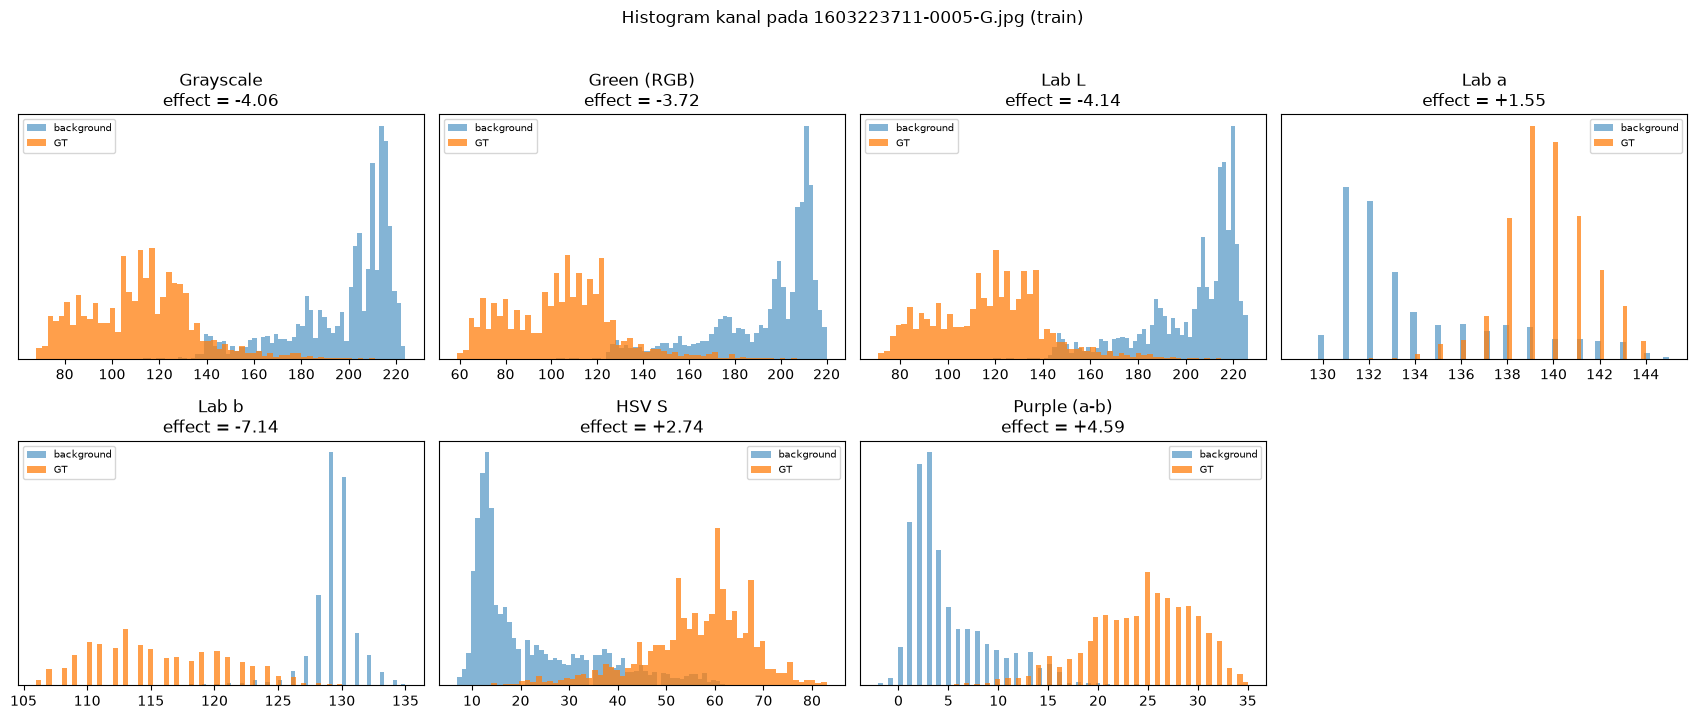

In [5]:
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (max(3, int(61 * SCALE)),) * 2
)

effect_rows = []
for rec in TRAIN:
    gt = rec['gt']
    ring = (cv2.dilate(gt.astype(np.uint8), kernel) > 0) & (~gt)
    chans = build_channels(rec)
    for name in CHANNELS:
        ch = chans[name]
        inside = ch[gt].astype(np.float32)
        outside = ch[ring].astype(np.float32)
        effect = (inside.mean() - outside.mean()) / (outside.std() + 1e-6)
        effect_rows.append({
            'image_id': rec['image_id'],
            'channel': name,
            'effect_size': float(effect),
            'abs_effect': float(abs(effect)),
        })

channel_effect = pd.DataFrame(effect_rows)
effect_summary = (
    channel_effect.groupby('channel', observed=True)['abs_effect']
    .agg(['mean', 'median', 'std'])
    .sort_values('mean', ascending=False)
    .round(3)
)
display(effect_summary)

# Histogram ditampilkan untuk satu citra train sebagai contoh.
demo = TRAIN[0]
chans = build_channels(demo)
gt = demo['gt']
ring = (cv2.dilate(gt.astype(np.uint8), kernel) > 0) & (~gt)

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
axes = axes.ravel()
for ax, name in zip(axes, CHANNELS):
    ch = chans[name]
    inside = ch[gt].astype(np.float32)
    outside = ch[ring].astype(np.float32)
    effect = (inside.mean() - outside.mean()) / (outside.std() + 1e-6)
    ax.hist(outside, bins=60, alpha=0.55, density=True, label='background')
    ax.hist(inside, bins=60, alpha=0.75, density=True, label='GT')
    ax.set_title(f"{CHANNEL_NAMES[name]}\neffect = {effect:+.2f}")
    ax.legend(fontsize=7)
    ax.set_yticks([])

axes[-1].axis('off')
plt.suptitle(f"Histogram kanal pada {demo['image_id']} (train)", y=1.02)
plt.tight_layout()
plt.show()

channel_effect.to_csv(RESULTS_DIR / 'channel_effect_size.csv', index=False)


## 5. Fungsi segmentasi, cleanup, dan metrik

Semua metode memakai cleanup minimal yang sama: komponen dengan luas di bawah
`MIN_AREA` dibuang. Tidak ada morphology atau object-level rule pada Eksperimen A.

Metrik objek memakai IoU >= 0,10 untuk mencocokkan komponen prediksi dengan objek GT.
Implementasi memakai contingency table sekali jalan agar tetap cepat ketika threshold
global menghasilkan ratusan atau ribuan komponen.

In [6]:
def min_cleanup(mask, min_area=MIN_AREA):
    mask = np.asarray(mask).astype(bool)
    if mask.sum() == 0:
        return mask
    return remove_small_objects(mask, max_size=max(1, min_area - 1), connectivity=2)


def seg_multiotsu(img_u8, classes=3, polarity='dark'):
    try:
        th = threshold_multiotsu(img_u8, classes=classes)
    except Exception:
        return np.zeros(img_u8.shape, dtype=bool)
    if polarity == 'dark':
        return img_u8 < th[0]
    return img_u8 > th[-1]


def seg_adaptive(img_u8, block=25, C=5, polarity='dark'):
    block = int(block)
    if block % 2 == 0:
        block += 1
    typ = cv2.THRESH_BINARY_INV if polarity == 'dark' else cv2.THRESH_BINARY
    return cv2.adaptiveThreshold(
        img_u8, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, typ, block, C
    ).astype(bool)


def pixel_metrics(pred, gt):
    pred = np.asarray(pred).astype(bool)
    gt = np.asarray(gt).astype(bool)
    tp = int(np.logical_and(pred, gt).sum())
    fp = int(np.logical_and(pred, ~gt).sum())
    fn = int(np.logical_and(~pred, gt).sum())
    dice = 2 * tp / (2 * tp + fp + fn + 1e-9)
    iou = tp / (tp + fp + fn + 1e-9)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    return {
        'dice': float(dice), 'iou': float(iou),
        'pixel_precision': float(precision), 'pixel_recall': float(recall),
        'tp': tp, 'fp': fp, 'fn': fn,
    }


def object_metrics(pred, gt_labels, iou_thr=OBJECT_IOU_THR):
    '''Object-level matching memakai IoU >= iou_thr, dihitung dari contingency table.'''
    pred = np.asarray(pred).astype(bool)
    pred_lab = label(pred, connectivity=2)
    n_pred = int(pred_lab.max())
    gt_ids = np.unique(gt_labels)
    gt_ids = gt_ids[gt_ids > 0]
    n_gt = int(len(gt_ids))

    if n_pred == 0 or n_gt == 0:
        return {
            'n_gt': n_gt, 'n_pred': n_pred,
            'gt_detected': 0, 'pred_matched': 0,
            'obj_recall': 0.0, 'obj_precision': 0.0, 'obj_fp': n_pred,
        }

    g = gt_labels.ravel().astype(np.int64)
    p = pred_lab.ravel().astype(np.int64)
    valid = (g > 0) & (p > 0)
    pair = g[valid] * (n_pred + 1) + p[valid]
    uniq, counts = np.unique(pair, return_counts=True)
    pair_gt = uniq // (n_pred + 1)
    pair_pred = uniq % (n_pred + 1)

    gt_areas = np.bincount(g, minlength=int(gt_ids.max()) + 1)
    pred_areas = np.bincount(p, minlength=n_pred + 1)

    best_gt = {}
    best_pred = {}
    for gid, pid, inter in zip(pair_gt.tolist(), pair_pred.tolist(), counts.tolist()):
        union = int(gt_areas[gid] + pred_areas[pid] - inter)
        if union <= 0:
            continue
        iou = inter / union
        if iou > best_gt.get(gid, 0.0):
            best_gt[gid] = iou
        if iou > best_pred.get(pid, 0.0):
            best_pred[pid] = iou

    detected = int(sum(v >= iou_thr for v in best_gt.values()))
    matched = int(sum(v >= iou_thr for v in best_pred.values()))
    return {
        'n_gt': n_gt, 'n_pred': n_pred,
        'gt_detected': detected, 'pred_matched': matched,
        'obj_recall': float(detected / n_gt),
        'obj_precision': float(matched / n_pred),
        'obj_fp': int(n_pred - matched),
    }


print('Fungsi segmentasi dan metrik siap.')

Fungsi segmentasi dan metrik siap.


## 6. Pemilihan kanal untuk Otsu dan adaptive threshold

Kanal dipilih **hanya dari 16 citra tuning**. Untuk setiap kanal dan metode,
dihitung Dice per citra, lalu dirata-ratakan. Kanal dengan rata-rata Dice tertinggi
dipakai untuk Otsu dan adaptive pada data uji.

k-means dan pixel-if-else tetap memakai vektor `[L, P, S]` karena membutuhkan
informasi warna, bukan satu kanal intensitas.

In [7]:
selection_rows = []
for rec in TRAIN:
    chans = build_channels(rec)
    for name in CHANNELS:
        u8 = channel_uint8(chans[name], name)
        masks = {
            'Otsu multilevel 3': seg_multiotsu(
                u8, classes=3, polarity=CHANNEL_POLARITY[name]
            ),
            'Adaptive threshold': seg_adaptive(
                u8, block=int(51 * SCALE), C=5, polarity=CHANNEL_POLARITY[name]
            ),
        }
        for method_name, mask in masks.items():
            pred = min_cleanup(mask)
            m = pixel_metrics(pred, rec['gt'])
            selection_rows.append({
                'image_id': rec['image_id'],
                'channel': name,
                'method': method_name,
                'dice': m['dice'],
                'iou': m['iou'],
                'pixel_precision': m['pixel_precision'],
                'pixel_recall': m['pixel_recall'],
            })

channel_selection = pd.DataFrame(selection_rows)
channel_summary = (
    channel_selection.groupby(['channel', 'method'], observed=True)['dice']
    .agg(['mean', 'median', 'std'])
    .round(4)
)
display(channel_summary)

channel_rank = (
    channel_selection.groupby('channel', observed=True)['dice'].mean()
    .sort_values(ascending=False)
)
print('Ranking kanal untuk threshold (mean Dice pada train):')
print(channel_rank.round(4).to_string())

SELECTED_CHANNEL = str(channel_rank.index[0])
print('\nKanal terpilih untuk Otsu/adaptive:', SELECTED_CHANNEL,
      f'({CHANNEL_NAMES[SELECTED_CHANNEL]})')

channel_selection.to_csv(RESULTS_DIR / 'channel_selection.csv', index=False)

mean  median     std
channel method                                    
L       Adaptive threshold  0.0494  0.0302  0.0730
        Otsu multilevel 3   0.0277  0.0193  0.0355
P       Adaptive threshold  0.0126  0.0084  0.0122
        Otsu multilevel 3   0.0282  0.0232  0.0230
S       Adaptive threshold  0.0077  0.0054  0.0064
        Otsu multilevel 3   0.0500  0.0160  0.0931
a       Adaptive threshold  0.0101  0.0063  0.0105
        Otsu multilevel 3   0.0202  0.0148  0.0189
b       Adaptive threshold  0.1658  0.1533  0.1205
        Otsu multilevel 3   0.1131  0.0358  0.1727
gray    Adaptive threshold  0.0499  0.0298  0.0751
        Otsu multilevel 3   0.0271  0.0193  0.0340
green   Adaptive threshold  0.0354  0.0268  0.0438
        Otsu multilevel 3   0.0246  0.0163  0.0290

Ranking kanal untuk threshold (mean Dice pada train):
channel
b        0.1395
L        0.0385
gray     0.0385
green    0.0300
S        0.0289
P        0.0204
a        0.0152

Kanal terpilih untuk Otsu/adaptive: b (Lab b)


## 7. Pixel-if-else sebagai metode tambahan

Pixel-if-else memakai tiga fitur ternormalisasi:
`L_n` (lightness), `P_n` (*purple score*), dan `S_n` (saturasi).

Aturannya:

```
mask = (L_n < t_L) & (P_n > t_P) & (S_n > t_S)
```

Threshold `t_L`, `t_P`, `t_S` dicari pada 16 citra tuning memakai weighted pixel sample:
foreground dan background disampel seimbang, lalu skor Dice dikoreksi dengan prevalensi
aslinya. Data uji tidak dipakai pada tahap ini.

In [8]:
def pixel_features(rec):
    ch = build_channels(rec)
    return {
        'L': ch['L'], 'P': ch['P'], 'S': ch['S'],
        'L_n': percentile_norm(ch['L']),
        'P_n': percentile_norm(ch['P']),
        'S_n': percentile_norm(ch['S']),
    }


def make_weighted_sample(gt, n_fg=15000, n_bg=15000, seed=SEED):
    g = np.asarray(gt).astype(bool).ravel()
    fg = np.flatnonzero(g)
    bg = np.flatnonzero(~g)
    rng = np.random.default_rng(seed)
    nf = min(len(fg), n_fg)
    nb = min(len(bg), n_bg)
    fi = rng.choice(fg, size=nf, replace=False)
    bi = rng.choice(bg, size=nb, replace=False)
    wf = len(fg) / max(nf, 1)
    wb = len(bg) / max(nb, 1)
    return fi, bi, wf, wb


def tune_pixel_ifelse(train_records, seed=SEED):
    bundles = []
    for rec in train_records:
        feat = pixel_features(rec)
        fi, bi, wf, wb = make_weighted_sample(rec['gt'], seed=seed)
        bundles.append({
            'Lf': feat['L_n'].ravel()[fi], 'Pf': feat['P_n'].ravel()[fi],
            'Sf': feat['S_n'].ravel()[fi],
            'Lb': feat['L_n'].ravel()[bi], 'Pb': feat['P_n'].ravel()[bi],
            'Sb': feat['S_n'].ravel()[bi],
            'wf': wf, 'wb': wb,
        })

    tLs = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
    tPs = [0.60, 0.70, 0.80, 0.90, 0.95]
    tSs = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
    best = None

    for tL in tLs:
        for tP in tPs:
            for tS in tSs:
                scores = []
                for b in bundles:
                    pf = (b['Lf'] < tL) & (b['Pf'] > tP) & (b['Sf'] > tS)
                    pb = (b['Lb'] < tL) & (b['Pb'] > tP) & (b['Sb'] > tS)
                    tp = pf.sum() * b['wf']
                    fn = (~pf).sum() * b['wf']
                    fp = pb.sum() * b['wb']
                    scores.append(2 * tp / (2 * tp + fp + fn + 1e-9))
                mean_score = float(np.mean(scores))
                if best is None or mean_score > best[0]:
                    best = (mean_score, tL, tP, tS)

    score, tL, tP, tS = best
    params = {
        't_L': float(tL), 't_P': float(tP), 't_S': float(tS),
        'use_texture': False, 't_core': 0.08,
    }
    return params, score


def pixel_mask(feat, params):
    m = (
        (feat['L_n'] < params['t_L']) &
        (feat['P_n'] > params['t_P']) &
        (feat['S_n'] > params['t_S'])
    )
    return m


if_else_params, if_else_train_score = tune_pixel_ifelse(TRAIN, seed=SEED)
print('Pixel-if-else params (tuning):', if_else_params)
print('Weighted train Dice         :', round(if_else_train_score, 4))

Pixel-if-else params (tuning): {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 'use_texture': False, 't_core': 0.08}
Weighted train Dice         : 0.2158


## 8. Eksperimen A - perbandingan metode segmentasi

Empat metode dievaluasi pada 16 citra uji (8 falciparum + 8 vivax), mencakup keempat stadium:
1. Otsu multilevel 3 kelas pada kanal terpilih,
2. Adaptive threshold pada kanal terpilih,
3. k-means k=3 pada `[L, P, S]`,
4. Pixel-if-else (metode tambahan) dengan threshold dari tuning.

Semua memakai cleanup minimal yang sama.

In [9]:
def seg_kmeans(feat, k=3, seed=SEED, max_sample=80000):
    L_n, P_n, S_n = feat['L_n'], feat['P_n'], feat['S_n']
    h, w = L_n.shape
    X = np.stack([L_n, P_n, S_n], axis=-1).reshape(-1, 3).astype(np.float32)

    rng = np.random.default_rng(seed)
    n = min(max_sample, len(X))
    idx = rng.choice(len(X), size=n, replace=False)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2)
    # Reset RNG tiap panggilan agar hasil tidak bergantung urutan pemanggilan.
    cv2.setRNGSeed(int(seed))
    _, _, centers = cv2.kmeans(
        X[idx], k, None, criteria, 3, cv2.KMEANS_PP_CENTERS
    )

    # Parasit: ungu (P tinggi), saturasi tinggi (S tinggi), relatif gelap (L rendah).
    score = centers[:, 1] + centers[:, 2] - 0.5 * centers[:, 0]
    chosen = int(np.argmax(score))

    labels = np.empty(len(X), dtype=np.uint8)
    for start in range(0, len(X), 500000):
        chunk = X[start:start + 500000]
        dist = ((chunk[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels[start:start + len(chunk)] = np.argmin(dist, axis=1)
    return labels.reshape(h, w) == chosen


METHODS = [
    'Otsu multilevel 3',
    'Adaptive threshold',
    'k-means k=3',
    'Pixel if-else (tambahan)',
]

exp_a_rows = []
a_masks = {}

for rec in TRAIN + TEST:
    chans = build_channels(rec)
    feat = pixel_features(rec)
    u8 = channel_uint8(chans[SELECTED_CHANNEL], SELECTED_CHANNEL)

    preds = {
        'Otsu multilevel 3': min_cleanup(
            seg_multiotsu(u8, classes=3, polarity=CHANNEL_POLARITY[SELECTED_CHANNEL])
        ),
        'Adaptive threshold': min_cleanup(
            seg_adaptive(
                u8, block=int(51 * SCALE), C=5,
                polarity=CHANNEL_POLARITY[SELECTED_CHANNEL],
            )
        ),
        'k-means k=3': min_cleanup(seg_kmeans(feat, k=3)),
        'Pixel if-else (tambahan)': min_cleanup(pixel_mask(feat, if_else_params)),
    }

    for method_name, pred in preds.items():
        pm = pixel_metrics(pred, rec['gt'])
        om = object_metrics(pred, rec['gt_labels'])
        exp_a_rows.append({
            'split': rec['split'],
            'image_id': rec['image_id'],
            'species': rec['species'],
            'stage': rec['stage'],
            'stages': ','.join(rec['stages']),
            'n_objects': rec['n_objects'],
            'method': method_name,
            **pm,
            **om,
        })
        if rec['split'] == 'test':
            a_masks[(rec['image_id'], method_name)] = pred

experiment_a = pd.DataFrame(exp_a_rows)

test_a = experiment_a[experiment_a['split'] == 'test'].copy()
display(
    test_a.groupby('method', observed=True)[['dice', 'iou', 'pixel_precision',
                                             'pixel_recall', 'obj_recall',
                                             'obj_precision', 'obj_fp']]
    .agg(['mean', 'median', 'std'])
    .round(4)
)

experiment_a.to_csv(RESULTS_DIR / 'experiment_a.csv', index=False)

dice                     iou                 pixel_precision                 pixel_recall                 obj_recall                 obj_precision  \
                            mean  median     std    mean  median     std            mean  median     std         mean  median     std       mean  median     std          mean   
method                                                                                                                                                                           
Adaptive threshold        0.1649  0.1713  0.1022  0.0932  0.0937  0.0637          0.2356  0.2183  0.1793       0.2044  0.1643  0.1059     0.2869  0.0000  0.4154        0.0246   
Otsu multilevel 3         0.0849  0.0271  0.1286  0.0495  0.0138  0.0828          0.0773  0.0138  0.1376       0.6675  0.8364  0.3270     0.8060  1.0000  0.3570        0.0724   
Pixel if-else (tambahan)  0.1998  0.0822  0.2490  0.1358  0.0432  0.1928          0.1995  0.0939  0.2386       0.2449  0.2058  0.2585     0.4644  0.2149  0.4974        0.0365   
k-means k=3               0.0252  0.0228  0.0158  0.0128  0.0115  0.0082          0.0147  0.0116  0.0109       0.7099  0.8620  0.3260     0.7629  1.0000  0.3708        0.0194   

                                            obj_fp                   
                          median     std      mean median       std  
method                                                               
Adaptive threshold        0.0000  0.0565  276.5000  153.5  269.7322  
Otsu multilevel 3         0.0075  0.1638  257.2500  262.0  171.9847  
Pixel if-else (tambahan)  0.0127  0.0466   50.6875   36.5   45.1792  
k-means k=3               0.0123  0.0179  183.3125  145.0  129.4886

## 9. Visualisasi overlay

GT berwarna hijau, prediksi berwarna merah. Area yang tumpang-tindih menjadi
campuran kuning/coklat. Visualisasi memakai downscale hanya untuk tampilan;
evaluasi tetap pada resolusi 50%.

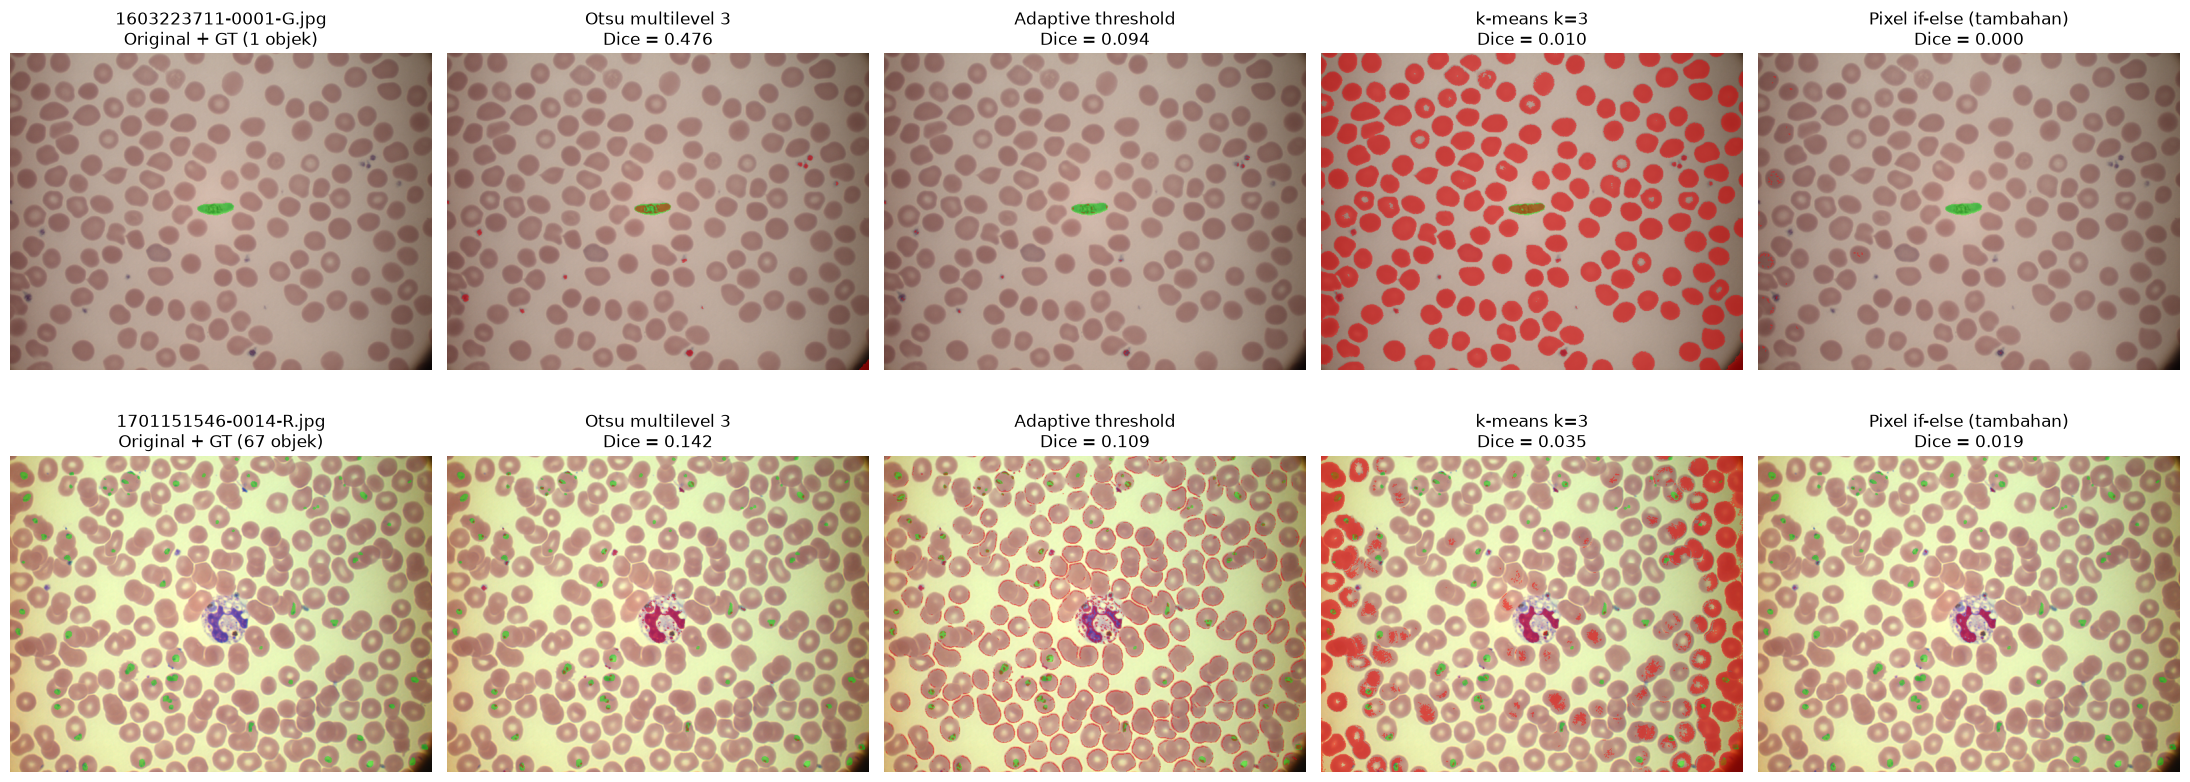

In [10]:
def overlay_small(bgr, gt, pred, width=640):
    h, w = bgr.shape[:2]
    scale = width / w
    nw, nh = width, max(1, int(h * scale))
    img = cv2.resize(bgr, (nw, nh), interpolation=cv2.INTER_AREA)
    g = cv2.resize(gt.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST) > 0
    p = cv2.resize(pred.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST) > 0

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)
    out = rgb.copy()
    out[g] = 0.55 * out[g] + 0.45 * np.array([0, 255, 0], dtype=np.float32)
    out[p] = 0.55 * out[p] + 0.45 * np.array([255, 0, 0], dtype=np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)


viz_recs = sorted(TEST, key=lambda r: r['n_objects'])
if len(viz_recs) > 2:
    viz_recs = [viz_recs[0], viz_recs[-1]]

fig, axes = plt.subplots(len(viz_recs), 1 + len(METHODS),
                         figsize=(22, 4.3 * len(viz_recs)), squeeze=False)

for row_i, rec in enumerate(viz_recs):
    axes[row_i, 0].imshow(overlay_small(rec['bgr'], rec['gt'], np.zeros_like(rec['gt'])))
    axes[row_i, 0].set_title(f"{rec['image_id']}\nOriginal + GT ({rec['n_objects']} objek)")
    axes[row_i, 0].axis('off')

    for col_i, method in enumerate(METHODS, start=1):
        pred = a_masks[(rec['image_id'], method)]
        d = pixel_metrics(pred, rec['gt'])['dice']
        axes[row_i, col_i].imshow(overlay_small(rec['bgr'], rec['gt'], pred))
        axes[row_i, col_i].set_title(f"{method}\nDice = {d:.3f}")
        axes[row_i, col_i].axis('off')

plt.tight_layout()
fig.savefig(RESULTS_DIR / 'experiment_a_overlay.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. Ringkasan hasil Eksperimen A dan penyimpanan

Tabel ringkas berisi mean, median, dan std pada 16 citra uji.
Angka ini bersifat eksploratif: subset stratified 2 citra per (spesies, stadium)
per split berarti tiap sel uji hanya diwakili 2 citra, sehingga angka per stadium
sangat bising dan dilaporkan sebagai indikasi, bukan klaim generalisasi.

In [11]:
summary_metrics = [
    'dice', 'iou', 'pixel_precision', 'pixel_recall',
    'obj_recall', 'obj_precision', 'obj_fp', 'n_pred',
]
per_image_dice = test_a.pivot_table(
    index='image_id', columns='method', values='dice'
).round(4)
print('Dice per citra uji:')
display(per_image_dice)

summary = (
    test_a.groupby('method', observed=True)[summary_metrics]
    .agg(['mean', 'median', 'std'])
    .round(4)
)
summary.columns = [f'{a}_{b}' for a, b in summary.columns]
summary = summary.reset_index()
display(summary)

summary.to_csv(RESULTS_DIR / 'experiment_a_summary.csv', index=False)

# Simpan metadata subset pada skala evaluasi (50%).
rec_by_id = {r['image_id']: r for r in records}
selected_out = selected.copy()
selected_out['stages'] = selected_out['stages'].apply(lambda s: ','.join(s))
selected_out['n_objects'] = selected_out['image_id'].map(lambda x: rec_by_id[x]['n_objects'])
selected_out['areas'] = selected_out['image_id'].map(
    lambda x: ','.join(map(str, rec_by_id[x]['areas']))
)
selected_out['total_area'] = selected_out['image_id'].map(
    lambda x: rec_by_id[x]['total_area']
)
selected_out['scale'] = SCALE
selected_out = selected_out.drop(columns=['width', 'height', 'image_path', 'ann_path'])
selected_out.to_csv(RESULTS_DIR / 'selected_images.csv', index=False)

with open(RESULTS_DIR / 'experiment_a_params.json', 'w') as f:
    json.dump({
        'seed': SEED,
        'scale': SCALE,
        'min_area': MIN_AREA,
        'object_iou_threshold': OBJECT_IOU_THR,
        'selected_channel': SELECTED_CHANNEL,
        'channel_polarity': CHANNEL_POLARITY,
        'adaptive_block': int(51 * SCALE),
        'adaptive_C': 5,
        'pixel_if_else_params': if_else_params,
        'pixel_if_else_weighted_train_dice': float(if_else_train_score),
    }, f, indent=2)

test_mean = test_a.groupby('method', observed=True)['dice'].mean().sort_values(ascending=False)
print('Ranking metode berdasarkan mean Dice pada test:')
print(test_mean.round(4).to_string())

main_methods = [m for m in METHODS if not m.startswith('Pixel')]
best_main = test_mean[main_methods].idxmax()
pixel_name = 'Pixel if-else (tambahan)'
pixel_mean = float(test_mean.get(pixel_name, np.nan))
best_main_mean = float(test_mean[best_main])
metric_means = test_a.groupby('method', observed=True)[
    ['dice', 'pixel_precision', 'pixel_recall', 'obj_recall', 'obj_precision', 'obj_fp']
].mean()

lines = [
    '# Ringkasan Eksperimen A',
    '',
    f'- Data: 32 citra (falciparum + vivax; 16 tuning, 16 uji; 2 per spesies x stadium x split), '
    f'resize {SCALE:.0%}.',
    f'- Kanal terpilih untuk Otsu/adaptive: `{SELECTED_CHANNEL}` ({CHANNEL_NAMES[SELECTED_CHANNEL]}).',
    f'- Metode utama terbaik pada test: `{best_main}` (mean Dice {best_main_mean:.4f}).',
    f'- Pixel-if-else (tambahan) mean Dice: {pixel_mean:.4f}.',
    '',
    '## Mean Dice per metode (test)',
    '',
    '```',
    test_mean.round(4).to_string(),
    '```',
    '',
    '## Catatan',
    '',
]
for method in ['Adaptive threshold', 'Otsu multilevel 3', 'k-means k=3',
               'Pixel if-else (tambahan)']:
    r = metric_means.loc[method]
    lines.append(
        f"- `{method}`: Dice {r['dice']:.4f}; pixel precision {r['pixel_precision']:.3f}, "
        f"pixel recall {r['pixel_recall']:.3f}; object recall {r['obj_recall']:.3f}, "
        f"object precision {r['obj_precision']:.3f}; FP objek {r['obj_fp']:.1f}/citra."
    )
lines += [
    '',
    '- Metode threshold global menangkap area luas (sel darah merah, tepi citra, artefak), '
    'sehingga pixel precision rendah meskipun recall piksel bisa tinggi.',
    '- Pixel-if-else menghasilkan komponen paling sedikit, tetapi recall-nya rendah: '
    'sebagian parasit tidak lolos ambang warna.',
    '- Eksperimen B (CLAHE, koreksi background, tekstur, kontrol negatif opening) dan Eksperimen C '
    '(morfologi, filter luas, object-level if-else) sudah dijalankan.',
]

# Rincian per spesies dan per stadium (test).
stage_breakdown = (
    test_a.groupby(['species', 'stage', 'method'], observed=True)['dice']
    .mean().round(4).unstack('method')
)
print('\nMean Dice per (spesies, stadium) pada test:')
display(stage_breakdown)
species_breakdown = (
    test_a.groupby(['species', 'method'], observed=True)['dice']
    .mean().round(4).unstack('method')
)
print('\nMean Dice per spesies pada test:')
display(species_breakdown)
stage_breakdown.to_csv(RESULTS_DIR / 'experiment_a_by_stage.csv')
species_breakdown.to_csv(RESULTS_DIR / 'experiment_a_by_species.csv')

(RESULTS_DIR / 'experiment_a_summary.md').write_text('\n'.join(lines))
print('\nFile tersimpan di:', RESULTS_DIR)
for p in sorted(RESULTS_DIR.glob('*')):
    print(' -', p.name)

Dice per citra uji:


method,Adaptive threshold,Otsu multilevel 3,Pixel if-else (tambahan),k-means k=3
image_id,,,,
1305121398-0005-T.jpg,0.0280,0.0045,0.0039,0.0068
1305121398-0010-S.jpg,0.3368,0.0205,0.0357,0.0138
1305121398-0012-S.jpg,0.0686,0.0221,0.0455,0.0079
1307210661-0010-R.jpg,0.1046,0.0043,0.0014,0.0296
1603223711-0001-G.jpg,0.0939,0.4763,0.0000,0.0099
1701151546-0008-R-T.jpg,0.0913,0.0266,0.0236,0.0202
1701151546-0014-R.jpg,0.1087,0.1420,0.0189,0.0348
1703121298-0001-G_R.jpg,0.3003,0.0610,0.7962,0.0338
1703121298-0002-S.jpg,0.1783,0.0277,0.6202,0.0157


,method,dice_mean,dice_median,dice_std,iou_mean,iou_median,iou_std,pixel_precision_mean,pixel_precision_median,pixel_precision_std,pixel_recall_mean,pixel_recall_median,pixel_recall_std,obj_recall_mean,obj_recall_median,obj_recall_std,obj_precision_mean,obj_precision_median,obj_precision_std,obj_fp_mean,obj_fp_median,obj_fp_std,n_pred_mean,n_pred_median,n_pred_std
0,Adaptive threshold,0.1649,0.1713,0.1022,0.0932,0.0937,0.0637,0.2356,0.2183,0.1793,0.2044,0.1643,0.1059,0.2869,0.0000,0.4154,0.0246,0.0000,0.0565,276.5000,153.5,269.7322,286.3750,173.0,282.0238
1,Otsu multilevel 3,0.0849,0.0271,0.1286,0.0495,0.0138,0.0828,0.0773,0.0138,0.1376,0.6675,0.8364,0.3270,0.8060,1.0000,0.3570,0.0724,0.0075,0.1638,257.2500,262.0,171.9847,263.2500,264.0,167.2553
2,Pixel if-else (tambahan),0.1998,0.0822,0.2490,0.1358,0.0432,0.1928,0.1995,0.0939,0.2386,0.2449,0.2058,0.2585,0.4644,0.2149,0.4974,0.0365,0.0127,0.0466,50.6875,36.5,45.1792,51.7500,38.0,45.1095
3,k-means k=3,0.0252,0.0228,0.0158,0.0128,0.0115,0.0082,0.0147,0.0116,0.0109,0.7099,0.8620,0.3260,0.7629,1.0000,0.3708,0.0194,0.0123,0.0179,183.3125,145.0,129.4886,186.4375,147.5,130.0923


Ranking metode berdasarkan mean Dice pada test:
method
Pixel if-else (tambahan)    0.1998
Adaptive threshold          0.1649
Otsu multilevel 3           0.0849
k-means k=3                 0.0252

Mean Dice per (spesies, stadium) pada test:


method                  Adaptive threshold  Otsu multilevel 3  Pixel if-else (tambahan)  k-means k=3
species    stage                                                                                    
falciparum gametocyte               0.2373             0.3893                    0.0070       0.0246
           ring                     0.1067             0.0732                    0.0101       0.0322
           schizont                 0.2027             0.0213                    0.0406       0.0108
           trophozoite              0.0597             0.0156                    0.0137       0.0135
vivax      gametocyte               0.2384             0.0734                    0.6020       0.0421
           ring                     0.1120             0.0252                    0.1450       0.0179
           schizont                 0.1794             0.0620                    0.5498       0.0386
           trophozoite              0.1830             0.0193                    0.2306       0.0216


Mean Dice per spesies pada test:


method,Adaptive threshold,Otsu multilevel 3,Pixel if-else (tambahan),k-means k=3
species,,,,
falciparum,0.1516,0.1248,0.0179,0.0203
vivax,0.1782,0.0450,0.3818,0.0301



File tersimpan di: /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/results/progress1
 - channel_effect_size.csv
 - channel_selection.csv
 - experiment_a.csv
 - experiment_a_by_species.csv
 - experiment_a_by_stage.csv
 - experiment_a_overlay.png
 - experiment_a_params.json
 - experiment_a_summary.csv
 - experiment_a_summary.md
 - experiment_b.csv
 - experiment_b_overlay.png
 - experiment_b_params.json
 - experiment_b_summary.csv
 - experiment_b_summary.md
 - experiment_c.csv
 - experiment_c_overlay.png
 - experiment_c_params.json
 - experiment_c_summary.csv
 - experiment_c_summary.md
 - selected_images.csv


## 11. Eksperimen B - pengaruh preprocessing

Eksperimen B menguji pengaruh tahap preprocessing. Sesuai prinsip "ubah satu blok
dalam satu waktu", **setiap metode mempertahankan formulasi Eksperimen A sebagai
baseline**-nya, lalu hanya tahap preprocessing yang divariasikan. Dengan begitu
efek preprocessing dapat dibandingkan murni di dalam tiap metode.

**Faktor yang dijaga tetap (sama untuk semua varian)**

- 32 citra yang sama, split 16 tuning / 16 uji, resize 50%, cleanup `MIN_AREA` yang sama.
- Kanal terpilih untuk Otsu/adaptive tetap `b`; k-means dan pixel-if-else tetap `[L, P, S]`.
- Semua parameter di-tuning hanya pada 16 citra tuning; citra uji hanya dievaluasi.

**Varian preprocessing (satu tahap ditambahkan pada satu waktu)**

| Varian | Isi |
| --- | --- |
| `B0_none` | kanal/fitur mentah, tanpa median |
| `B1_median` | median 3x3 (baseline Eksperimen A) |
| `B2_gaussian` | Gaussian 3x3 sebagai pembanding restorasi |
| `B3_clahe` | + CLAHE pada L / kanal terpilih |
| `B4_bg_closing` | + koreksi background dengan closing besar, lalu dibagi |
| `B5_bg_opening` | + koreksi background dengan **opening** (kontrol negatif) |
| `B6_combo` | kombinasi koreksi background (closing) + CLAHE |
| `B7_texture` | + fitur tekstur GLCM/LBP/statistik lokal (hanya metode berbasis fitur) |

`B7_texture` tidak berlaku untuk Otsu/adaptive karena keduanya hanya ambang satu kanal;
untuk Otsu/adaptive baris tekstur ditandai `n/a`.

In [12]:
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

POLARITY = CHANNEL_POLARITY[SELECTED_CHANNEL]
BLOCK_TEX = max(4, int(round(32 * SCALE)))   # blok GLCM/LBP pada skala 50%
LEVELS = 16
LOCAL_KSIZE = max(3, int(round(31 * SCALE)))  # window statistik lokal


def gaussian3(x):
    return cv2.GaussianBlur(x, (3, 3), 0)


def apply_clahe(x, clip=2.0, tile=8):
    clahe = cv2.createCLAHE(clipLimit=float(clip), tileGridSize=(int(tile), int(tile)))
    return clahe.apply(x)


def estimate_background(x, mode='closing', down=4, frac=0.08):
    '''Estimasi iluminasi latar dengan closing/opening besar pada citra downscale.'''
    h, w = x.shape
    sw, sh = max(1, w // down), max(1, h // down)
    small = cv2.resize(x, (sw, sh), interpolation=cv2.INTER_AREA)
    k = int(round(min(sw, sh) * frac))
    k = max(15, k)
    if k % 2 == 0:
        k += 1
    k = min(k, min(sw, sh))
    if k % 2 == 0:
        k -= 1
    k = max(3, k)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    op = cv2.MORPH_CLOSE if mode == 'closing' else cv2.MORPH_OPEN
    bg = cv2.morphologyEx(small, op, kernel)
    return cv2.resize(bg, (w, h), interpolation=cv2.INTER_LINEAR)


def correct_background(x, bg):
    out = x.astype(np.float32) / (bg.astype(np.float32) + 1e-6) * 255.0
    return np.clip(out, 0, 255).astype(np.uint8)


def local_std(x, ksize=LOCAL_KSIZE):
    xf = x.astype(np.float32)
    mean = cv2.boxFilter(xf, -1, (ksize, ksize))
    mean2 = cv2.boxFilter(xf * xf, -1, (ksize, ksize))
    return np.sqrt(np.maximum(mean2 - mean * mean, 0.0))


def texture_score(x_u8, block=BLOCK_TEX, levels=LEVELS):
    '''Skor tekstur: kombinasi statistik lokal, GLCM contrast, dan LBP entropy.'''
    sd_n = percentile_norm(local_std(x_u8))
    h, w = x_u8.shape
    contrast = np.zeros((h, w), np.float32)
    entropy = np.zeros((h, w), np.float32)
    for y0 in range(0, h, block):
        for x0 in range(0, w, block):
            crop = x_u8[y0:y0 + block, x0:x0 + block]
            if crop.shape[0] < 4 or crop.shape[1] < 4:
                continue
            q = np.clip((crop.astype(np.float32) / (256.0 / levels)).astype(np.uint8),
                        0, levels - 1)
            g = graycomatrix(q, distances=[1, 2],
                             angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                             levels=levels, symmetric=True, normed=True)
            c = float(graycoprops(g, 'contrast').mean())
            lbp = local_binary_pattern(crop, 8, 1, method='uniform').astype(np.uint8)
            hist = np.bincount(lbp.ravel(), minlength=10).astype(np.float64)
            p = hist / (hist.sum() + 1e-9)
            nz = p[p > 0]
            e = float(-(nz * np.log2(nz)).sum())
            contrast[y0:y0 + crop.shape[0], x0:x0 + crop.shape[1]] = c
            entropy[y0:y0 + crop.shape[0], x0:x0 + crop.shape[1]] = e
    return (0.5 * sd_n + 0.25 * percentile_norm(contrast)
            + 0.25 * percentile_norm(entropy)).astype(np.float32)


def raw_channels(rec):
    lab = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    S = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2HSV)[:, :, 1]
    return L, a, b, S


def prep_channel(rec, variant):
    '''Representasi satu kanal (untuk Otsu/adaptive) sesuai varian preprocessing.'''
    L, a, b, S = raw_channels(rec)
    base = {'L': L, 'a': a, 'b': b, 'S': S}[SELECTED_CHANNEL]
    if variant == 'B0_none':
        return base
    base = median3(base)
    if variant == 'B1_median':
        return base
    if variant == 'B2_gaussian':
        return gaussian3(base)
    if variant == 'B3_clahe':
        return apply_clahe(base)
    if variant == 'B4_bg_closing':
        return correct_background(base, estimate_background(base, 'closing'))
    if variant == 'B5_bg_opening':
        return correct_background(base, estimate_background(base, 'opening'))
    if variant == 'B6_combo':
        return apply_clahe(correct_background(base, estimate_background(base, 'closing')))
    raise ValueError(f'variant tidak berlaku untuk satu kanal: {variant}')


def prep_features(rec, variant, use_texture=False):
    '''Representasi fitur (untuk k-means/pixel-if-else) sesuai varian preprocessing.'''
    L, a, b, S = raw_channels(rec)
    if variant == 'B0_none':
        Lp, ap, bp, Sp = L, a, b, S
    elif variant == 'B1_median':
        Lp, ap, bp, Sp = median3(L), median3(a), median3(b), median3(S)
    elif variant == 'B2_gaussian':
        Lp, ap, bp, Sp = gaussian3(L), gaussian3(a), gaussian3(b), gaussian3(S)
    elif variant == 'B3_clahe':
        Lp, ap, bp, Sp = apply_clahe(median3(L)), median3(a), median3(b), median3(S)
    elif variant == 'B4_bg_closing':
        Lm = median3(L)
        Lp = correct_background(Lm, estimate_background(Lm, 'closing'))
        ap, bp, Sp = median3(a), median3(b), median3(S)
    elif variant == 'B5_bg_opening':
        Lm = median3(L)
        Lp = correct_background(Lm, estimate_background(Lm, 'opening'))
        ap, bp, Sp = median3(a), median3(b), median3(S)
    elif variant == 'B6_combo':
        Lm = median3(L)
        Lp = apply_clahe(correct_background(Lm, estimate_background(Lm, 'closing')))
        ap, bp, Sp = median3(a), median3(b), median3(S)
    elif variant == 'B7_texture':
        Lp, ap, bp, Sp = median3(L), median3(a), median3(b), median3(S)
    else:
        raise ValueError(f'variant tidak dikenal: {variant}')

    P = ap.astype(np.float32) - bp.astype(np.float32)
    feat = {
        'L': Lp, 'P': P, 'S': Sp,
        'L_n': percentile_norm(Lp), 'P_n': percentile_norm(P), 'S_n': percentile_norm(Sp),
    }
    if use_texture:
        feat['T_n'] = texture_score(Lp)
    return feat


def tune_adaptive(train_records, variant):
    blocks = [15, 25, 51, 75]
    Cs = [2, 5, 10]
    best = None
    for blk in blocks:
        for C in Cs:
            scores = []
            for rec in train_records:
                u8 = prep_channel(rec, variant)
                pred = min_cleanup(seg_adaptive(u8, block=blk, C=C, polarity=POLARITY))
                scores.append(pixel_metrics(pred, rec['gt'])['dice'])
            m = float(np.mean(scores))
            if best is None or m > best[0]:
                best = (m, blk, C)
    return {'block': int(best[1]), 'C': int(best[2])}, float(best[0])


def tune_ifelse_variant(train_records, variant, use_texture, seed=SEED):
    bundles = []
    for rec in train_records:
        feat = prep_features(rec, variant, use_texture=use_texture)
        fi, bi, wf, wb = make_weighted_sample(rec['gt'], seed=seed)
        b = {
            'Lf': feat['L_n'].ravel()[fi], 'Pf': feat['P_n'].ravel()[fi],
            'Sf': feat['S_n'].ravel()[fi],
            'Lb': feat['L_n'].ravel()[bi], 'Pb': feat['P_n'].ravel()[bi],
            'Sb': feat['S_n'].ravel()[bi], 'wf': wf, 'wb': wb,
        }
        if use_texture:
            b['Tf'] = feat['T_n'].ravel()[fi]
            b['Tb'] = feat['T_n'].ravel()[bi]
        bundles.append(b)

    tLs = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
    tPs = [0.60, 0.70, 0.80, 0.90, 0.95]
    tSs = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
    tTs = [0.50, 0.65, 0.80] if use_texture else [None]
    best = None
    for tL in tLs:
        for tP in tPs:
            for tS in tSs:
                for tT in tTs:
                    scores = []
                    for b in bundles:
                        pf = (b['Lf'] < tL) & (b['Pf'] > tP) & (b['Sf'] > tS)
                        pb = (b['Lb'] < tL) & (b['Pb'] > tP) & (b['Sb'] > tS)
                        if use_texture:
                            pf = pf & (b['Tf'] > tT)
                            pb = pb & (b['Tb'] > tT)
                        tp = pf.sum() * b['wf']
                        fn = (~pf).sum() * b['wf']
                        fp = pb.sum() * b['wb']
                        scores.append(2 * tp / (2 * tp + fp + fn + 1e-9))
                    m = float(np.mean(scores))
                    if best is None or m > best[0]:
                        best = (m, tL, tP, tS, tT)
    score, tL, tP, tS, tT = best
    params = {
        't_L': float(tL), 't_P': float(tP), 't_S': float(tS),
        't_T': (None if tT is None else float(tT)),
        'use_texture': bool(use_texture),
    }
    return params, float(score)


def pixel_mask_variant(feat, params):
    m = ((feat['L_n'] < params['t_L'])
         & (feat['P_n'] > params['t_P'])
         & (feat['S_n'] > params['t_S']))
    if params.get('use_texture') and params.get('t_T') is not None:
        m = m & (feat['T_n'] > params['t_T'])
    return m


def seg_kmeans_variant(feat, use_texture=False, k=3, seed=SEED, max_sample=80000):
    feats = [feat['L_n'], feat['P_n'], feat['S_n']]
    if use_texture:
        feats.append(feat['T_n'])
    h, w = feat['L_n'].shape
    X = np.stack(feats, axis=-1).reshape(-1, len(feats)).astype(np.float32)
    rng = np.random.default_rng(seed)
    n = min(max_sample, len(X))
    idx = rng.choice(len(X), size=n, replace=False)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2)
    cv2.setRNGSeed(int(seed))  # sama dengan Eksperimen A -> B1 mereproduksi A
    _, _, centers = cv2.kmeans(X[idx], k, None, criteria, 3, cv2.KMEANS_PP_CENTERS)
    score = centers[:, 1] + centers[:, 2] - 0.5 * centers[:, 0]
    chosen = int(np.argmax(score))
    labels = np.empty(len(X), dtype=np.uint8)
    for s in range(0, len(X), 500000):
        chunk = X[s:s + 500000]
        dist = ((chunk[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels[s:s + len(chunk)] = np.argmin(dist, axis=1)
    return labels.reshape(h, w) == chosen


def predict_b(rec, method, variant, ad_params_map, if_params_map):
    use_tex = (variant == 'B7_texture')
    if method == 'Otsu multilevel 3':
        return min_cleanup(seg_multiotsu(prep_channel(rec, variant), classes=3, polarity=POLARITY))
    if method == 'Adaptive threshold':
        p = ad_params_map[variant]
        return min_cleanup(seg_adaptive(prep_channel(rec, variant),
                                        block=p['block'], C=p['C'], polarity=POLARITY))
    if method == 'k-means k=3':
        return min_cleanup(seg_kmeans_variant(prep_features(rec, variant, use_tex),
                                              use_texture=use_tex))
    if method == 'Pixel if-else (tambahan)':
        return min_cleanup(pixel_mask_variant(prep_features(rec, variant, use_tex),
                                              if_params_map[variant]))
    raise ValueError(method)


print('Fungsi Eksperimen B siap.')
print('Polarity:', POLARITY, '| block tekstur:', BLOCK_TEX, '| window lokal:', LOCAL_KSIZE)

Fungsi Eksperimen B siap.
Polarity: dark | block tekstur: 16 | window lokal: 16


### 11.1 Demo preprocessing pada satu citra tuning

Panel memperlihatkan pengaruh tiap tahap pada crop di sekitar GT: median, Gaussian,
CLAHE, koreksi background dengan closing, kontrol negatif dengan opening, dan
skor tekstur.

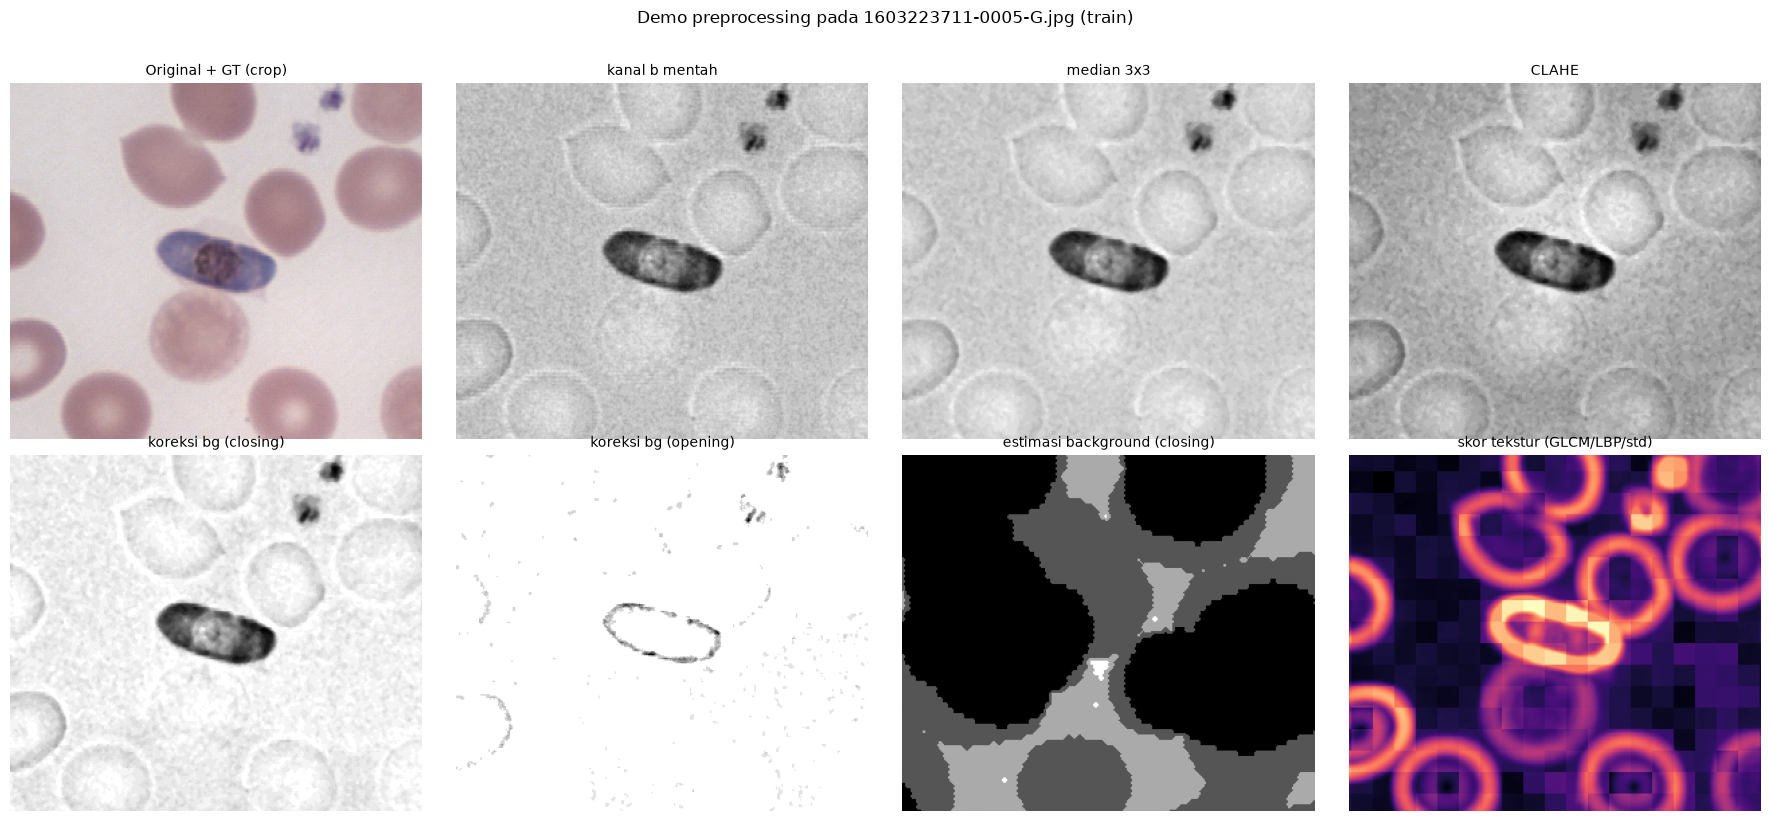

In [13]:
demo = TRAIN[0]
ys, xs = np.where(demo['gt'])
pad = max(40, int(220 * SCALE))
y0, y1 = max(0, ys.min() - pad), min(demo['shape'][0], ys.max() + pad)
x0, x1 = max(0, xs.min() - pad), min(demo['shape'][1], xs.max() + pad)


def crop(x):
    return x[y0:y1, x0:x1]


L, a, b, S = raw_channels(demo)
ch_b = median3(b)
bg_close = estimate_background(ch_b, 'closing')
bg_open = estimate_background(ch_b, 'opening')
tex = texture_score(median3(L))

rgb = cv2.cvtColor(crop(demo['bgr']), cv2.COLOR_BGR2RGB)
panels = [
    (rgb, 'Original + GT (crop)', None),
    (crop(b), 'kanal b mentah', 'gray'),
    (crop(ch_b), 'median 3x3', 'gray'),
    (crop(apply_clahe(ch_b)), 'CLAHE', 'gray'),
    (crop(correct_background(ch_b, bg_close)), 'koreksi bg (closing)', 'gray'),
    (crop(correct_background(ch_b, bg_open)), 'koreksi bg (opening)', 'gray'),
    (crop(bg_close), 'estimasi background (closing)', 'gray'),
    (crop(tex), 'skor tekstur (GLCM/LBP/std)', 'magma'),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (img, title, cmap) in zip(axes.ravel(), panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.axis('off')
plt.suptitle(f"Demo preprocessing pada {demo['image_id']} (train)", y=1.02)
plt.tight_layout()
plt.show()

### 11.2 Pemeriksaan parameter (hanya data tuning)

Supaya efek preprocessing benar-benar terisolasi, **parameter metode ditahan tetap
pada nilai Eksperimen A**:

- Adaptive threshold: `block = 25`, `C = 5` (nilai Eksperimen A), sama untuk semua varian.
- Pixel-if-else: `t_L`, `t_P`, `t_S` dari hasil tuning Eksperimen A (Bagian 7), sama untuk semua varian non-tekstur.
- Batch Otsu, k-means: tidak punya parameter tambahan.

Satu-satunya parameter baru adalah `t_T` untuk varian tekstur (`B7_texture`), karena
fitur tekstur belum ada pada Eksperimen A. `t_T` dipilih dari grid pada 16 citra tuning.

Dengan demikian perbedaan antar varian di dalam satu metode hanya berasal dari
preprocessing, bukan dari tuning parameter yang berbeda.


In [14]:
VARIANT_ORDER = [
    'B0_none', 'B1_median', 'B2_gaussian', 'B3_clahe',
    'B4_bg_closing', 'B5_bg_opening', 'B6_combo', 'B7_texture',
]
SINGLE_CHANNEL_METHODS = ['Otsu multilevel 3', 'Adaptive threshold']
FEATURE_METHODS = ['k-means k=3', 'Pixel if-else (tambahan)']
METHODS_B = SINGLE_CHANNEL_METHODS + FEATURE_METHODS

# Parameter metode ditahan pada nilai Eksperimen A.
FIXED_ADAPTIVE = {'block': int(51 * SCALE), 'C': 5}
BASE_IF = {
    't_L': float(if_else_params['t_L']),
    't_P': float(if_else_params['t_P']),
    't_S': float(if_else_params['t_S']),
    't_T': None, 'use_texture': False,
}


def adaptive_train_dice(train_records, variant):
    scores = []
    for rec in train_records:
        pred = min_cleanup(seg_adaptive(
            prep_channel(rec, variant),
            block=FIXED_ADAPTIVE['block'], C=FIXED_ADAPTIVE['C'], polarity=POLARITY,
        ))
        scores.append(pixel_metrics(pred, rec['gt'])['dice'])
    return float(np.mean(scores))


def ifelse_train_dice(train_records, variant, params):
    scores = []
    for rec in train_records:
        feat = prep_features(rec, variant, use_texture=params.get('use_texture', False))
        pred = min_cleanup(pixel_mask_variant(feat, params))
        scores.append(pixel_metrics(pred, rec['gt'])['dice'])
    return float(np.mean(scores))


def tune_texture_threshold(train_records):
    best = None
    for tT in [0.50, 0.65, 0.80]:
        params = {**BASE_IF, 't_T': float(tT), 'use_texture': True}
        s = ifelse_train_dice(train_records, 'B7_texture', params)
        if best is None or s > best[0]:
            best = (s, tT)
    return {**BASE_IF, 't_T': float(best[1]), 'use_texture': True}, float(best[0])


ad_params_map = {v: dict(FIXED_ADAPTIVE) for v in VARIANT_ORDER if v != 'B7_texture'}
if_params_map = {}
b_tuning_rows = []

for variant in VARIANT_ORDER:
    use_tex = (variant == 'B7_texture')
    if use_tex:
        params, score = tune_texture_threshold(TRAIN)
        ad_score = np.nan
    else:
        params = dict(BASE_IF)
        score = ifelse_train_dice(TRAIN, variant, params)
        ad_score = adaptive_train_dice(TRAIN, variant)
    if_params_map[variant] = params
    b_tuning_rows.append({
        'variant': variant,
        'adaptive_block': ad_params_map.get(variant, {}).get('block', np.nan),
        'adaptive_C': ad_params_map.get(variant, {}).get('C', np.nan),
        'adaptive_train_dice': ad_score,
        'ifelse_t_L': params['t_L'], 'ifelse_t_P': params['t_P'],
        'ifelse_t_S': params['t_S'], 'ifelse_t_T': params['t_T'],
        'ifelse_train_score': score,
    })
    print(f"{variant:14s} | adaptive {ad_params_map.get(variant)} ({ad_score:.4f}) | "
          f"if-else {params} (train Dice {score:.4f})")

b_tuning = pd.DataFrame(b_tuning_rows)
display(b_tuning.round(4))


B0_none        | adaptive {'block': 25, 'C': 5} (0.1531) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': None, 'use_texture': False} (train Dice 0.2387)


B1_median      | adaptive {'block': 25, 'C': 5} (0.1658) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': None, 'use_texture': False} (train Dice 0.2324)


B2_gaussian    | adaptive {'block': 25, 'C': 5} (0.1779) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': None, 'use_texture': False} (train Dice 0.2285)


B3_clahe       | adaptive {'block': 25, 'C': 5} (0.0618) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': None, 'use_texture': False} (train Dice 0.2333)


B4_bg_closing  | adaptive {'block': 25, 'C': 5} (0.1255) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': None, 'use_texture': False} (train Dice 0.2224)


B5_bg_opening  | adaptive {'block': 25, 'C': 5} (0.1147) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': None, 'use_texture': False} (train Dice 0.1350)


B6_combo       | adaptive {'block': 25, 'C': 5} (0.0404) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': None, 'use_texture': False} (train Dice 0.2242)


B7_texture     | adaptive None (nan) | if-else {'t_L': 0.6, 't_P': 0.95, 't_S': 0.8, 't_T': 0.5, 'use_texture': True} (train Dice 0.2128)


,variant,adaptive_block,adaptive_C,adaptive_train_dice,ifelse_t_L,ifelse_t_P,ifelse_t_S,ifelse_t_T,ifelse_train_score
0,B0_none,25.0,5.0,0.1531,0.6,0.95,0.8,NaN,0.2387
1,B1_median,25.0,5.0,0.1658,0.6,0.95,0.8,NaN,0.2324
2,B2_gaussian,25.0,5.0,0.1779,0.6,0.95,0.8,NaN,0.2285
3,B3_clahe,25.0,5.0,0.0618,0.6,0.95,0.8,NaN,0.2333
4,B4_bg_closing,25.0,5.0,0.1255,0.6,0.95,0.8,NaN,0.2224
5,B5_bg_opening,25.0,5.0,0.1147,0.6,0.95,0.8,NaN,0.1350
6,B6_combo,25.0,5.0,0.0404,0.6,0.95,0.8,NaN,0.2242
7,B7_texture,NaN,NaN,NaN,0.6,0.95,0.8,0.5,0.2128


### 11.3 Evaluasi seluruh varian pada seluruh subset

Untuk setiap metode dan setiap varian dihitung metrik piksel dan objek pada
32 citra (16 tuning + 16 uji). Pemilihan varian terbaik per metode memakai
**mean Dice pada 16 citra tuning**; citra uji hanya dilaporkan, tidak dipakai memilih.

In [15]:
b_rows = []
for variant in VARIANT_ORDER:
    use_tex = (variant == 'B7_texture')
    applicable = FEATURE_METHODS if use_tex else METHODS_B
    for method in applicable:
        for rec in TRAIN + TEST:
            pred = predict_b(rec, method, variant, ad_params_map, if_params_map)
            pm = pixel_metrics(pred, rec['gt'])
            om = object_metrics(pred, rec['gt_labels'])
            b_rows.append({
                'split': rec['split'],
                'image_id': rec['image_id'],
                'species': rec['species'],
                'stage': rec['stage'],
                'stages': ','.join(rec['stages']),
                'n_objects': rec['n_objects'],
                'method': method,
                'variant': variant,
                'texture': use_tex,
                **pm,
                **om,
            })

experiment_b = pd.DataFrame(b_rows)
experiment_b.to_csv(RESULTS_DIR / 'experiment_b.csv', index=False)

b_metrics = ['dice', 'iou', 'pixel_precision', 'pixel_recall',
             'obj_recall', 'obj_precision', 'obj_fp', 'n_pred']

test_b = experiment_b[experiment_b['split'] == 'test'].copy()
train_b = experiment_b[experiment_b['split'] == 'train'].copy()

train_rank = (train_b.groupby(['method', 'variant'], observed=True)['dice'].mean())
best_variant = train_rank.groupby('method', observed=True).idxmax().apply(lambda x: x[1])

print('Varian terbaik per metode (dipilih dari mean Dice pada train):')
for method, variant in best_variant.items():
    print(f'  {method:26s} -> {variant}  (train Dice {train_rank[(method, variant)]:.4f})')

test_mean_b = (test_b.groupby(['method', 'variant'], observed=True)['dice']
               .mean().round(4).unstack())
print('\nMean Dice pada test - baris metode, kolom varian:')
display(test_mean_b)

Varian terbaik per metode (dipilih dari mean Dice pada train):
  Adaptive threshold         -> B2_gaussian  (train Dice 0.1779)
  Otsu multilevel 3          -> B4_bg_closing  (train Dice 0.1785)
  Pixel if-else (tambahan)   -> B0_none  (train Dice 0.2387)
  k-means k=3                -> B5_bg_opening  (train Dice 0.0445)

Mean Dice pada test - baris metode, kolom varian:


variant,B0_none,B1_median,B2_gaussian,B3_clahe,B4_bg_closing,B5_bg_opening,B6_combo,B7_texture
method,,,,,,,,
Adaptive threshold,0.1601,0.1649,0.1707,0.0660,0.1151,0.1201,0.0449,NaN
Otsu multilevel 3,0.0649,0.0849,0.0841,0.0583,0.2644,0.1047,0.1201,NaN
Pixel if-else (tambahan),0.2095,0.1998,0.1999,0.1999,0.1995,0.1054,0.1981,0.1766
k-means k=3,0.0258,0.0252,0.0252,0.0301,0.0548,0.0325,0.0345,0.0281


### 11.4 Visualisasi: baseline vs varian terbaik per metode

Panel membandingkan hasil `B1_median` (baseline Eksperimen A) dengan varian terbaik
tiap metode pada satu citra uji. GT hijau, prediksi merah.

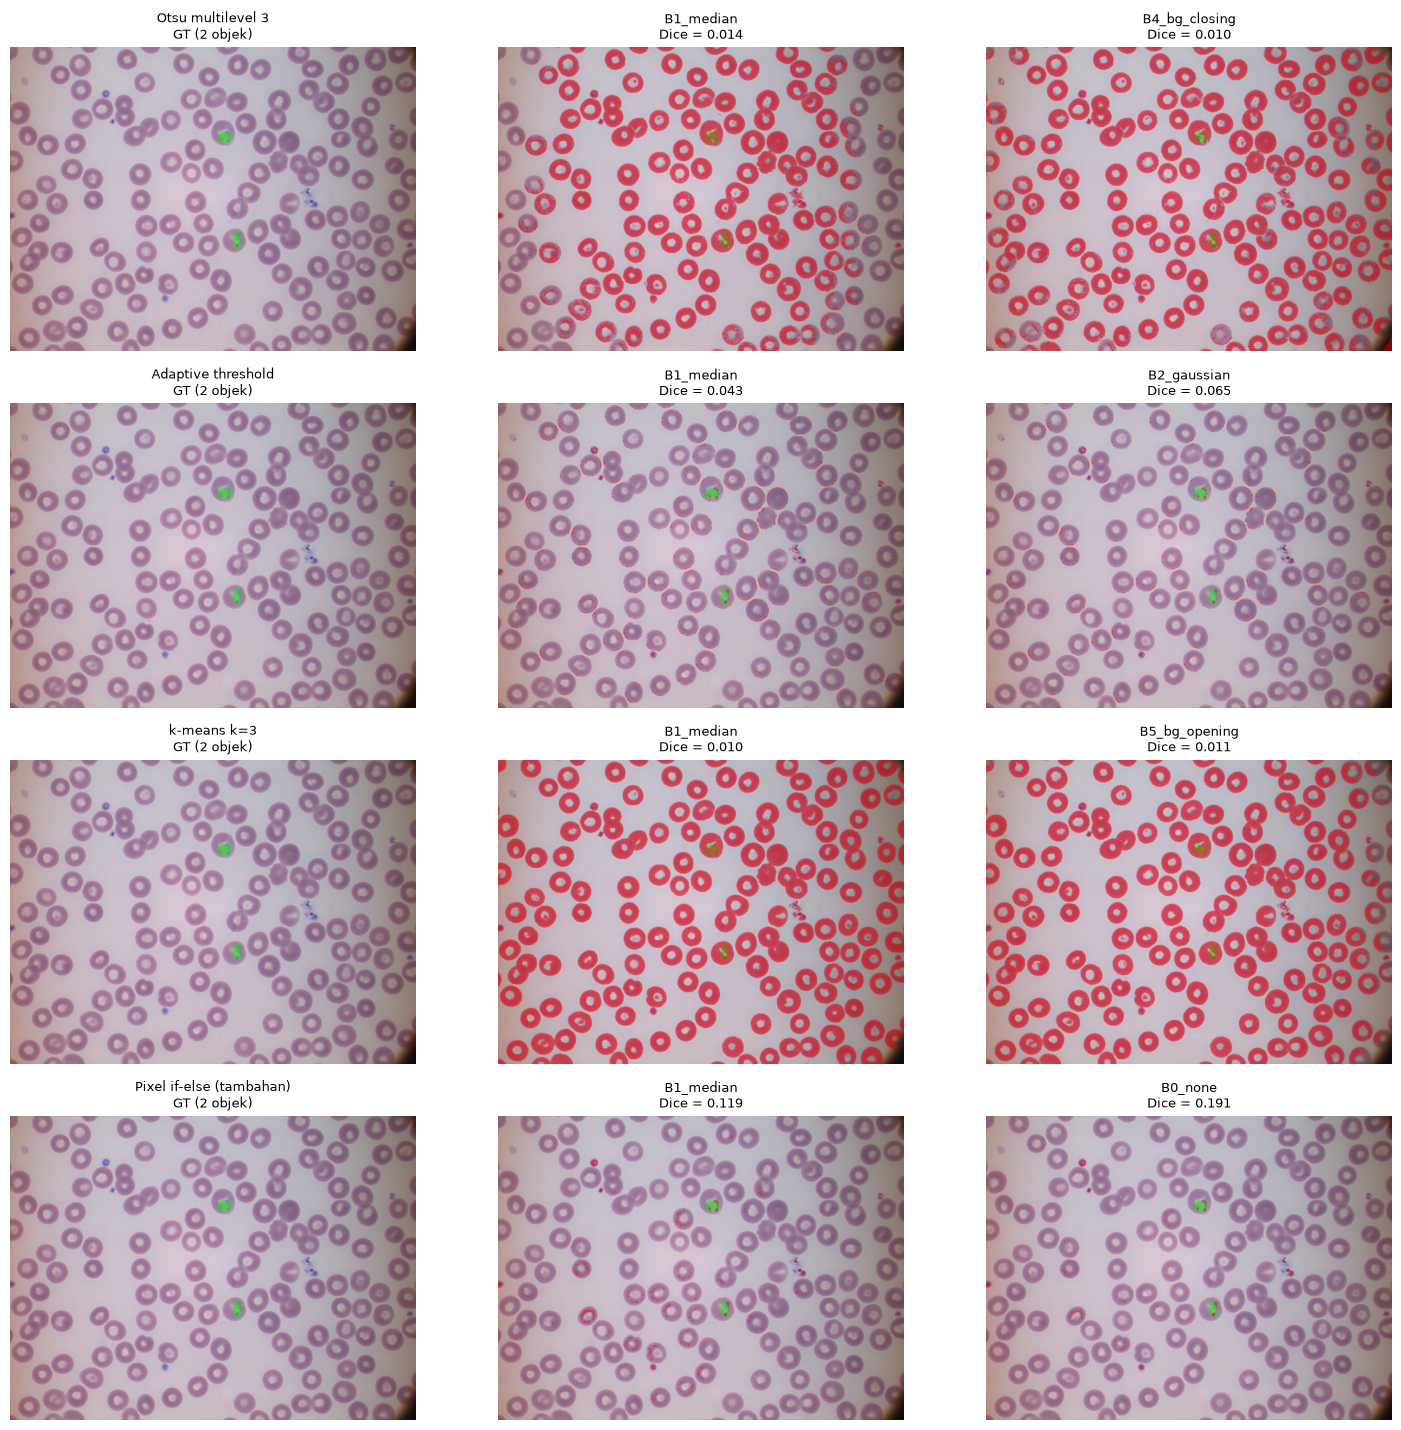

Citra contoh: 1703121298-0006-R.jpg


In [16]:
viz_rec = sorted(TEST, key=lambda r: r['n_objects'])[len(TEST) // 2]
fig, axes = plt.subplots(len(METHODS_B), 3, figsize=(15, 3.6 * len(METHODS_B)))

for row_i, method in enumerate(METHODS_B):
    axes[row_i, 0].imshow(overlay_small(viz_rec['bgr'], viz_rec['gt'], np.zeros_like(viz_rec['gt'])))
    axes[row_i, 0].set_title(f"{method}\nGT ({viz_rec['n_objects']} objek)", fontsize=9)
    axes[row_i, 0].axis('off')

    base_pred = predict_b(viz_rec, method, 'B1_median', ad_params_map, if_params_map)
    d_base = pixel_metrics(base_pred, viz_rec['gt'])['dice']
    axes[row_i, 1].imshow(overlay_small(viz_rec['bgr'], viz_rec['gt'], base_pred))
    axes[row_i, 1].set_title(f'B1_median\nDice = {d_base:.3f}', fontsize=9)
    axes[row_i, 1].axis('off')

    bv = best_variant[method]
    if bv == 'B1_median':
        axes[row_i, 2].imshow(overlay_small(viz_rec['bgr'], viz_rec['gt'], base_pred))
        axes[row_i, 2].set_title('(sama dengan baseline)', fontsize=9)
    else:
        best_pred = predict_b(viz_rec, method, bv, ad_params_map, if_params_map)
        d_best = pixel_metrics(best_pred, viz_rec['gt'])['dice']
        axes[row_i, 2].imshow(overlay_small(viz_rec['bgr'], viz_rec['gt'], best_pred))
        axes[row_i, 2].set_title(f'{bv}\nDice = {d_best:.3f}', fontsize=9)
    axes[row_i, 2].axis('off')

plt.tight_layout()
fig.savefig(RESULTS_DIR / 'experiment_b_overlay.png', dpi=120, bbox_inches='tight')
plt.show()
print('Citra contoh:', viz_rec['image_id'])

### 11.5 Ringkasan Eksperimen B dan penyimpanan

Ringkasan mean/median/std pada 16 citra uji untuk setiap pasangan metode-varian,
ditambah ringkasan varian terbaik per metode.

In [17]:
summary_b = (
    test_b.groupby(['method', 'variant'], observed=True)[b_metrics]
    .agg(['mean', 'median', 'std'])
    .round(4)
)
summary_b.columns = [f'{a}_{b}' for a, b in summary_b.columns]
summary_b = summary_b.reset_index()
summary_b.to_csv(RESULTS_DIR / 'experiment_b_summary.csv', index=False)

best_rows = []
for method in METHODS_B:
    for variant in VARIANT_ORDER:
        if (method, variant) not in train_rank.index:
            continue
        r = test_b[(test_b['method'] == method) & (test_b['variant'] == variant)]
        base_r = test_b[(test_b['method'] == method) & (test_b['variant'] == 'B1_median')]
        best_rows.append({
            'method': method,
            'variant': variant,
            'selected_from_train': bool(variant == best_variant[method]),
            'train_mean_dice': float(train_rank[(method, variant)]),
            'test_mean_dice': float(r['dice'].mean()),
            'test_mean_obj_recall': float(r['obj_recall'].mean()),
            'test_mean_obj_precision': float(r['obj_precision'].mean()),
            'test_mean_obj_fp': float(r['obj_fp'].mean()),
            'delta_test_dice_vs_B1': float(r['dice'].mean() - base_r['dice'].mean()),
        })
best_table = pd.DataFrame(best_rows)
display(best_table.round(4))

with open(RESULTS_DIR / 'experiment_b_params.json', 'w') as f:
    json.dump({
        'seed': SEED,
        'scale': SCALE,
        'min_area': MIN_AREA,
        'object_iou_threshold': OBJECT_IOU_THR,
        'selected_channel': SELECTED_CHANNEL,
        'polarity': POLARITY,
        'block_texture': BLOCK_TEX,
        'levels_glcm': LEVELS,
        'local_ksize': LOCAL_KSIZE,
        'variants': VARIANT_ORDER,
        'adaptive_params': ad_params_map,
        'ifelse_params': if_params_map,
        'best_variant_per_method': {k: str(v) for k, v in best_variant.items()},
    }, f, indent=2)

lines = [
    '# Ringkasan Eksperimen B',
    '',
    f'- Data: 32 citra (falciparum + vivax; 16 tuning, 16 uji), resize {SCALE:.0%}.',
    f'- Kanal terpilih: `{SELECTED_CHANNEL}`; polaritas `{POLARITY}`.',
    '- Setiap metode mempertahankan formulasi Eksperimen A sebagai baseline; hanya '
    'preprocessing yang divariasikan (faktor lain tetap).',
    '- Pemilihan varian terbaik per metode memakai mean Dice pada train (16 citra tuning).',
    '',
    '## Varian terbaik per metode (dipilih dari train)',
    '',
]
for method in METHODS_B:
    v = best_variant[method]
    tr = train_rank[(method, v)]
    base_r = test_b[(test_b['method'] == method) & (test_b['variant'] == 'B1_median')]
    r = test_b[(test_b['method'] == method) & (test_b['variant'] == v)]
    delta = r['dice'].mean() - base_r['dice'].mean()
    lines.append(
        f"- `{method}`: varian `{v}` (train Dice {tr:.4f}); "
        f"test Dice {r['dice'].mean():.4f} vs B1_median "
        f"{base_r['dice'].mean():.4f} (delta {delta:+.4f})."
    )
lines += [
    '',
    '## Mean Dice pada test per metode x varian',
    '',
    '```',
    test_mean_b.round(4).to_string(),
    '```',
    '',
    '## Catatan',
    '',
    '- `B5_bg_opening` adalah kontrol negatif: jika closing benar, varian opening '
    'seharusnya tidak lebih baik.',
    '- `B7_texture` hanya berlaku untuk k-means dan pixel-if-else; Otsu/adaptive '
    'tidak dijalankan pada varian tekstur.',
    '- Selisih Dice antar varian kecil dan berasal dari 16 citra uji; hasil tetap '
    'eksploratif, bukan klaim generalisasi.',
    '- Eksperimen C (morfologi pasca-segmentasi, tiga ambang luas, object-level '
    'if-else) dijalankan pada sel berikutnya.',
]
(RESULTS_DIR / 'experiment_b_summary.md').write_text('\n'.join(lines))
print('Tersimpan:', RESULTS_DIR / 'experiment_b_summary.md')
for p in sorted(RESULTS_DIR.glob('*')):
    print(' -', p.name)

,method,variant,selected_from_train,train_mean_dice,test_mean_dice,test_mean_obj_recall,test_mean_obj_precision,test_mean_obj_fp,delta_test_dice_vs_B1
0,Otsu multilevel 3,B0_none,False,0.1111,0.0649,0.8296,0.0619,380.1875,-0.0200
1,Otsu multilevel 3,B1_median,False,0.1131,0.0849,0.8060,0.0724,257.2500,0.0000
2,Otsu multilevel 3,B2_gaussian,False,0.1163,0.0841,0.8058,0.0736,217.1875,-0.0008
3,Otsu multilevel 3,B3_clahe,False,0.0671,0.0583,0.8053,0.0244,689.6250,-0.0266
4,Otsu multilevel 3,B4_bg_closing,True,0.1785,0.2644,0.9092,0.1239,350.2500,0.1795
5,Otsu multilevel 3,B5_bg_opening,False,0.1116,0.1047,0.0473,0.0286,37.8125,0.0198
6,Otsu multilevel 3,B6_combo,False,0.1079,0.1201,0.9616,0.0465,726.4375,0.0352
7,Adaptive threshold,B0_none,False,0.1531,0.1601,0.2848,0.0190,402.9375,-0.0048
8,Adaptive threshold,B1_median,False,0.1658,0.1649,0.2869,0.0246,276.5000,0.0000
9,Adaptive threshold,B2_gaussian,True,0.1779,0.1707,0.2841,0.0299,197.3750,0.0058


Tersimpan: /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/results/progress1/experiment_b_summary.md
 - channel_effect_size.csv
 - channel_selection.csv
 - experiment_a.csv
 - experiment_a_by_species.csv
 - experiment_a_by_stage.csv
 - experiment_a_overlay.png
 - experiment_a_params.json
 - experiment_a_summary.csv
 - experiment_a_summary.md
 - experiment_b.csv
 - experiment_b_overlay.png
 - experiment_b_params.json
 - experiment_b_summary.csv
 - experiment_b_summary.md
 - experiment_c.csv
 - experiment_c_overlay.png
 - experiment_c_params.json
 - experiment_c_summary.csv
 - experiment_c_summary.md
 - selected_images.csv


## 12. Eksperimen C - pengaruh morfologi pasca-segmentasi

Eksperimen C menguji tahap **pasca-segmentasi** dengan menjaga blok sebelumnya tetap.
Dua basis segmentasi dipakai:

1. **Adaptive threshold** pada kanal `b` (metode utama terbaik Eksperimen A).
2. **Pixel if-else** (metode tambahan), karena object-level if-else paling relevan
   diterapkan pada output yang sudah dipilih berdasarkan warna.

Mask mentah (sebelum cleanup apa pun) dibandingkan dengan beberapa perlakuan:

| Varian | Perlakuan |
| --- | --- |
| `C0_raw` | tanpa pasca-segmentasi |
| `C1_opening` | opening 3x3 (menghapus tonjolan/titik kecil) |
| `C2_closing` | closing 3x3 (menutup lubang kecil) |
| `C3_open_close` | opening lalu closing |
| `C4_area_min` | filter luas `MIN_AREA` (baseline Eksperimen A) |
| `C5_area_small` | filter luas ambang kecil |
| `C6_area_medium` | filter luas ambang sedang |
| `C7_area_large` | filter luas ambang besar |
| `C8_object_ifelse` | object-level if-else pada fitur tiap komponen |
| `C9_open_area_med` | opening lalu filter luas sedang |

Tiga ambang luas (`small`, `medium`, `large`) ditentukan dari distribusi luas objek
GT pada **16 citra tuning** (persentil 1, 5, dan 10), sehingga ambang bersifat
data-driven. Object-level if-else memakai aturan per komponen: luas minimal serta
rata-rata skor *purple* (`P_n`) dan saturasi (`S_n`) minimal; parameternya dituning
hanya pada citra tuning. Karena filter luas besar berpotensi menghapus parasit asli,
perubahan object recall ikut dilaporkan.

In [18]:
KERNEL3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

_gt_areas_train = np.concatenate(
    [np.asarray(r['areas'], dtype=int) for r in TRAIN if len(r['areas']) > 0]
)
AREA_MIN = int(MIN_AREA)
AREA_SMALL = int(max(MIN_AREA + 1, round(np.percentile(_gt_areas_train, 1))))
AREA_MEDIUM = int(max(AREA_SMALL + 1, round(np.percentile(_gt_areas_train, 5))))
AREA_LARGE = int(max(AREA_MEDIUM + 1, round(np.percentile(_gt_areas_train, 10))))

AREA_THRESHOLDS = {
    'C4_area_min': AREA_MIN,
    'C5_area_small': AREA_SMALL,
    'C6_area_medium': AREA_MEDIUM,
    'C7_area_large': AREA_LARGE,
}

C_VARIANTS = [
    'C0_raw', 'C1_opening', 'C2_closing', 'C3_open_close',
    'C4_area_min', 'C5_area_small', 'C6_area_medium', 'C7_area_large',
    'C8_object_ifelse', 'C9_open_area_med',
]
C_BASE_METHODS = ['Adaptive threshold', 'Pixel if-else (tambahan)']

print('Ambang luas (px pada skala 50%, dari GT train):')
print('  min    =', AREA_MIN)
print('  small  =', AREA_SMALL, '(persentil 1)')
print('  medium =', AREA_MEDIUM, '(persentil 5)')
print('  large  =', AREA_LARGE, '(persentil 10)')


def raw_segmentation(rec, base):
    '''Mask segmentasi sebelum pasca-segmentasi, identik dengan Eksperimen A.'''
    if base == 'Adaptive threshold':
        u8 = build_channels(rec)[SELECTED_CHANNEL]
        return seg_adaptive(
            u8, block=int(51 * SCALE), C=5,
            polarity=CHANNEL_POLARITY[SELECTED_CHANNEL],
        )
    if base == 'Pixel if-else (tambahan)':
        return pixel_mask(pixel_features(rec), if_else_params)
    raise ValueError(base)


def object_ifelse_mask(mask, feat, params):
    '''Object-level if-else: simpan komponen yang lolos ambang luas/warna.'''
    lab, n = label(mask.astype(np.uint8), connectivity=2, return_num=True)
    if n == 0:
        return mask.astype(bool)
    flat = lab.ravel()
    area = np.bincount(flat, minlength=n + 1)
    Psum = np.bincount(flat, weights=feat['P_n'].ravel(), minlength=n + 1)
    Ssum = np.bincount(flat, weights=feat['S_n'].ravel(), minlength=n + 1)
    meanP = Psum / np.maximum(area, 1)
    meanS = Ssum / np.maximum(area, 1)
    keep = np.zeros(n + 1, dtype=bool)
    keep[1:] = (
        (area[1:] >= params['min_area'])
        & (meanP[1:] >= params['t_P'])
        & (meanS[1:] >= params['t_S'])
    )
    return keep[lab]


def postprocess(mask, variant, feat, obj_params):
    m = mask.astype(np.uint8)
    if variant == 'C0_raw':
        return mask.astype(bool)
    if variant == 'C1_opening':
        return cv2.morphologyEx(m, cv2.MORPH_OPEN, KERNEL3) > 0
    if variant == 'C2_closing':
        return cv2.morphologyEx(m, cv2.MORPH_CLOSE, KERNEL3) > 0
    if variant == 'C3_open_close':
        o = cv2.morphologyEx(m, cv2.MORPH_OPEN, KERNEL3)
        return cv2.morphologyEx(o, cv2.MORPH_CLOSE, KERNEL3) > 0
    if variant in AREA_THRESHOLDS:
        return min_cleanup(mask, AREA_THRESHOLDS[variant])
    if variant == 'C8_object_ifelse':
        return object_ifelse_mask(mask, feat, obj_params)
    if variant == 'C9_open_area_med':
        o = cv2.morphologyEx(m, cv2.MORPH_OPEN, KERNEL3) > 0
        return min_cleanup(o, AREA_THRESHOLDS['C6_area_medium'])
    raise ValueError(variant)


# Tuning object-level if-else hanya pada 16 citra tuning, per basis segmentasi.
obj_params_map = {}
for base in C_BASE_METHODS:
    best = None
    for min_area in [0, MIN_AREA, AREA_SMALL]:
        for tP in [0.20, 0.35, 0.50]:
            for tS in [0.20, 0.35, 0.50]:
                params = {'min_area': int(min_area), 't_P': float(tP), 't_S': float(tS)}
                scores = []
                for rec in TRAIN:
                    raw = raw_segmentation(rec, base)
                    feat = pixel_features(rec)
                    pred = object_ifelse_mask(raw, feat, params)
                    scores.append(pixel_metrics(pred, rec['gt'])['dice'])
                s = float(np.mean(scores))
                if best is None or s > best[0]:
                    best = (s, params)
    obj_params_map[base] = best[1]
    print(f"Object-if-else {base:26s} -> {best[1]} (train Dice {best[0]:.4f})")

Ambang luas (px pada skala 50%, dari GT train):
  min    = 12
  small  = 64 (persentil 1)
  medium = 110 (persentil 5)
  large  = 249 (persentil 10)


Object-if-else Adaptive threshold         -> {'min_area': 64, 't_P': 0.5, 't_S': 0.2} (train Dice 0.1531)


Object-if-else Pixel if-else (tambahan)   -> {'min_area': 64, 't_P': 0.2, 't_S': 0.2} (train Dice 0.2537)


### 12.1 Evaluasi seluruh varian pasca-segmentasi

Setiap pasangan (basis, varian) dievaluasi pada 16 citra tuning dan 16 citra uji.
Pemilihan varian terbaik per basis memakai mean Dice pada tuning; citra uji hanya
dilaporkan. Selain Dice/IoU, dicatat jumlah komponen sebelum dan sesudah serta
object recall untuk melihat apakah parasit asli ikut terhapus.

In [19]:
# Precompute mask mentah dan fitur sekali agar evaluasi cepat.
raw_masks = {}
raw_components = {}
feats = {}
for rec in TRAIN + TEST:
    feats[rec['image_id']] = pixel_features(rec)
    for base in C_BASE_METHODS:
        m = raw_segmentation(rec, base)
        raw_masks[(base, rec['image_id'])] = m
        raw_components[(base, rec['image_id'])] = int(
            label(m.astype(np.uint8), connectivity=2).max()
        )

c_rows = []
for base in C_BASE_METHODS:
    for variant in C_VARIANTS:
        for rec in TRAIN + TEST:
            raw = raw_masks[(base, rec['image_id'])]
            pred = postprocess(raw, variant, feats[rec['image_id']], obj_params_map[base])
            pm = pixel_metrics(pred, rec['gt'])
            om = object_metrics(pred, rec['gt_labels'])
            n_post = int(label(pred.astype(np.uint8), connectivity=2).max())
            c_rows.append({
                'split': rec['split'],
                'image_id': rec['image_id'],
                'species': rec['species'],
                'stage': rec['stage'],
                'n_objects': rec['n_objects'],
                'base_method': base,
                'variant': variant,
                'n_components_raw': raw_components[(base, rec['image_id'])],
                'n_components_post': n_post,
                **pm,
                **om,
            })

experiment_c = pd.DataFrame(c_rows)
experiment_c.to_csv(RESULTS_DIR / 'experiment_c.csv', index=False)

c_metrics = ['dice', 'iou', 'pixel_precision', 'pixel_recall',
             'obj_recall', 'obj_precision', 'obj_fp',
             'n_components_raw', 'n_components_post']

train_c = experiment_c[experiment_c['split'] == 'train']
test_c = experiment_c[experiment_c['split'] == 'test']

train_rank_c = train_c.groupby(['base_method', 'variant'], observed=True)['dice'].mean()
best_variant_c = train_rank_c.groupby('base_method', observed=True).idxmax().apply(lambda x: x[1])

print('Varian pasca-segmentasi terbaik per basis (dipilih dari train):')
for base, variant in best_variant_c.items():
    print(f'  {base:26s} -> {variant:18s} (train Dice {train_rank_c[(base, variant)]:.4f})')

test_mean_c = (test_c.groupby(['base_method', 'variant'], observed=True)['dice']
               .mean().round(4).unstack())
print('\nMean Dice pada test - baris basis, kolom varian:')
display(test_mean_c)

Varian pasca-segmentasi terbaik per basis (dipilih dari train):
  Adaptive threshold         -> C5_area_small      (train Dice 0.1767)
  Pixel if-else (tambahan)   -> C7_area_large      (train Dice 0.2833)

Mean Dice pada test - baris basis, kolom varian:


variant,C0_raw,C1_opening,C2_closing,C3_open_close,C4_area_min,C5_area_small,C6_area_medium,C7_area_large,C8_object_ifelse,C9_open_area_med
base_method,,,,,,,,,,
Adaptive threshold,0.1450,0.1629,0.1462,0.1636,0.1649,0.1443,0.0825,0.0478,0.1385,0.0752
Pixel if-else (tambahan),0.1946,0.2018,0.1947,0.2025,0.1998,0.1991,0.1923,0.1819,0.1991,0.1948


### 12.2 Visualisasi dan ringkasan Eksperimen C

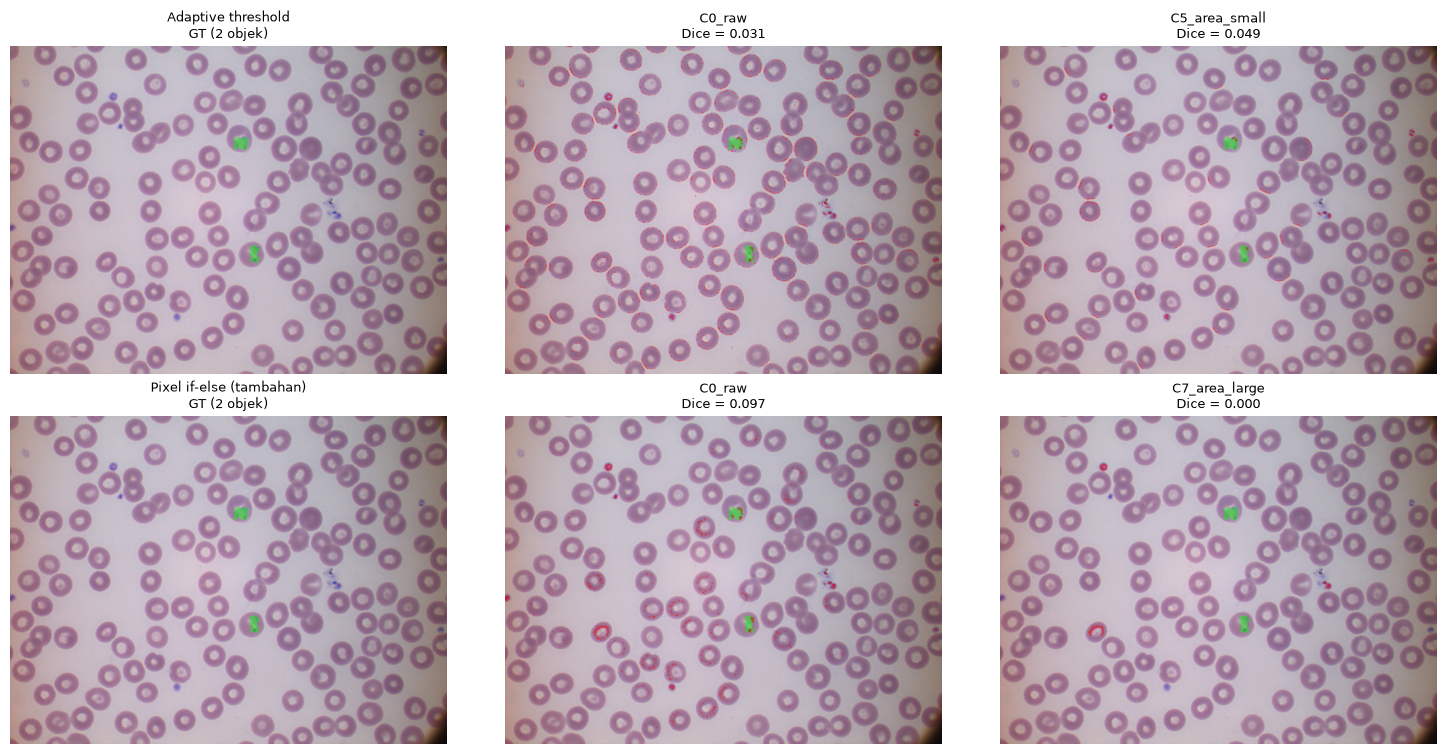

Citra contoh: 1703121298-0006-R.jpg
Tersimpan: /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/results/progress1/experiment_c_summary.md


,base_method,variant,selected_from_train,train_mean_dice,test_mean_dice,test_mean_obj_recall,test_mean_obj_precision,test_mean_n_components_raw,test_mean_n_components_post,delta_dice_vs_raw,delta_obj_recall_vs_raw
0,Adaptive threshold,C0_raw,False,0.1446,0.1450,0.2879,0.0087,1407.875,1407.8750,0.0000,0.0000
1,Adaptive threshold,C1_opening,False,0.1661,0.1629,0.2814,0.0151,1407.875,505.0625,0.0179,-0.0064
2,Adaptive threshold,C2_closing,False,0.1457,0.1462,0.3513,0.0095,1407.875,1328.1250,0.0012,0.0634
3,Adaptive threshold,C3_open_close,False,0.1667,0.1636,0.2829,0.0160,1407.875,487.6875,0.0186,-0.0049
4,Adaptive threshold,C4_area_min,False,0.1658,0.1649,0.2869,0.0246,1407.875,286.3750,0.0199,-0.0009
5,Adaptive threshold,C5_area_small,True,0.1767,0.1443,0.2300,0.0575,1407.875,52.5000,-0.0007,-0.0578
6,Adaptive threshold,C6_area_medium,False,0.1560,0.0825,0.1738,0.0747,1407.875,28.8750,-0.0625,-0.1141
7,Adaptive threshold,C7_area_large,False,0.0694,0.0478,0.0740,0.0444,1407.875,8.5000,-0.0972,-0.2138
8,Adaptive threshold,C8_object_ifelse,False,0.1531,0.1385,0.1890,0.0630,1407.875,36.3750,-0.0065,-0.0989
9,Adaptive threshold,C9_open_area_med,False,0.1437,0.0752,0.1556,0.0849,1407.875,21.6875,-0.0698,-0.1322


In [20]:
viz_rec_c = sorted(TEST, key=lambda r: r['n_objects'])[len(TEST) // 2]
fig, axes = plt.subplots(len(C_BASE_METHODS), 3,
                         figsize=(15, 3.8 * len(C_BASE_METHODS)), squeeze=False)
for row_i, base in enumerate(C_BASE_METHODS):
    raw = raw_masks[(base, viz_rec_c['image_id'])]
    axes[row_i, 0].imshow(overlay_small(
        viz_rec_c['bgr'], viz_rec_c['gt'], np.zeros_like(viz_rec_c['gt'])))
    axes[row_i, 0].set_title(
        f"{base}\nGT ({viz_rec_c['n_objects']} objek)", fontsize=9)
    axes[row_i, 0].axis('off')

    axes[row_i, 1].imshow(overlay_small(viz_rec_c['bgr'], viz_rec_c['gt'], raw))
    axes[row_i, 1].set_title(
        f'C0_raw\nDice = {pixel_metrics(raw, viz_rec_c["gt"])["dice"]:.3f}', fontsize=9)
    axes[row_i, 1].axis('off')

    bv = best_variant_c[base]
    bp = postprocess(raw, bv, feats[viz_rec_c['image_id']], obj_params_map[base])
    axes[row_i, 2].imshow(overlay_small(viz_rec_c['bgr'], viz_rec_c['gt'], bp))
    axes[row_i, 2].set_title(
        f'{bv}\nDice = {pixel_metrics(bp, viz_rec_c["gt"])["dice"]:.3f}', fontsize=9)
    axes[row_i, 2].axis('off')

plt.tight_layout()
fig.savefig(RESULTS_DIR / 'experiment_c_overlay.png', dpi=120, bbox_inches='tight')
plt.show()
print('Citra contoh:', viz_rec_c['image_id'])

summary_c = (
    test_c.groupby(['base_method', 'variant'], observed=True)[c_metrics]
    .agg(['mean', 'median', 'std']).round(4)
)
summary_c.columns = [f'{a}_{b}' for a, b in summary_c.columns]
summary_c = summary_c.reset_index()
summary_c.to_csv(RESULTS_DIR / 'experiment_c_summary.csv', index=False)

rows_c = []
for base in C_BASE_METHODS:
    for variant in C_VARIANTS:
        r = test_c[(test_c['base_method'] == base) & (test_c['variant'] == variant)]
        raw_r = test_c[(test_c['base_method'] == base) & (test_c['variant'] == 'C0_raw')]
        rows_c.append({
            'base_method': base,
            'variant': variant,
            'selected_from_train': bool(variant == best_variant_c[base]),
            'train_mean_dice': float(train_rank_c[(base, variant)]),
            'test_mean_dice': float(r['dice'].mean()),
            'test_mean_obj_recall': float(r['obj_recall'].mean()),
            'test_mean_obj_precision': float(r['obj_precision'].mean()),
            'test_mean_n_components_raw': float(r['n_components_raw'].mean()),
            'test_mean_n_components_post': float(r['n_components_post'].mean()),
            'delta_dice_vs_raw': float(r['dice'].mean() - raw_r['dice'].mean()),
            'delta_obj_recall_vs_raw': float(r['obj_recall'].mean() - raw_r['obj_recall'].mean()),
        })
c_table = pd.DataFrame(rows_c)

with open(RESULTS_DIR / 'experiment_c_params.json', 'w') as f:
    json.dump({
        'seed': SEED,
        'scale': SCALE,
        'selected_channel': SELECTED_CHANNEL,
        'base_methods': C_BASE_METHODS,
        'variants': C_VARIANTS,
        'area_thresholds_px': {
            'min': AREA_MIN, 'small': AREA_SMALL,
            'medium': AREA_MEDIUM, 'large': AREA_LARGE,
        },
        'area_threshold_percentiles': {'small': 1, 'medium': 5, 'large': 10},
        'opening_closing_kernel': 3,
        'object_ifelse_params': obj_params_map,
        'best_variant_per_base': {k: str(v) for k, v in best_variant_c.items()},
        'pixel_if_else_params': if_else_params,
    }, f, indent=2)

lines = [
    '# Ringkasan Eksperimen C',
    '',
    f'- Data: 32 citra (falciparum + vivax; 16 tuning, 16 uji), resize {SCALE:.0%}.',
    '- Dua basis: Adaptive threshold (metode utama) dan Pixel if-else (metode tambahan).',
    f'- Ambang luas dari GT train: kecil {AREA_SMALL} px, sedang {AREA_MEDIUM} px, '
    f'besar {AREA_LARGE} px; `MIN_AREA` = {AREA_MIN} px.',
    '- Pemilihan varian terbaik per basis memakai mean Dice pada train.',
    '',
    '## Varian terbaik per basis (dipilih dari train)',
    '',
]
for base in C_BASE_METHODS:
    v = best_variant_c[base]
    r = test_c[(test_c['base_method'] == base) & (test_c['variant'] == v)]
    raw_r = test_c[(test_c['base_method'] == base) & (test_c['variant'] == 'C0_raw')]
    lines.append(
        f"- `{base}`: varian `{v}` (train Dice {train_rank_c[(base, v)]:.4f}); "
        f"test Dice {r['dice'].mean():.4f} vs raw {raw_r['dice'].mean():.4f}; "
        f"object recall {r['obj_recall'].mean():.3f} vs raw {raw_r['obj_recall'].mean():.3f}."
    )
lines += [
    '',
    '## Mean Dice pada test per basis x varian',
    '',
    '```',
    test_mean_c.round(4).to_string(),
    '```',
    '',
    '## Catatan',
    '',
    '- `C4_area_min` memakai `MIN_AREA` yang sama dengan Eksperimen A, sehingga '
    'harus mereproduksi Dice Eksperimen A untuk kedua basis.',
    '- Filter luas besar berpotensi menghapus parasit asli; lihat penurunan object '
    'recall pada tabel `experiment_c_summary.csv`.',
    '- Object-level if-else hanya memakai luas dan rata-rata warna per komponen; '
    'parameter dituning pada 16 citra tuning.',
    '- Selisih Dice berasal dari 16 citra uji; hasil tetap eksploratif.',
]
(RESULTS_DIR / 'experiment_c_summary.md').write_text('\n'.join(lines))
print('Tersimpan:', RESULTS_DIR / 'experiment_c_summary.md')
display(c_table.round(4))

## 13. Keterbatasan dan langkah berikutnya

**Keterbatasan tahap ini**
- Subset stratified 32 citra (2 falciparum + 2 vivax per stadium per split); hasil
  belum mengklaim generalisasi.
- Tiap sel (spesies, stadium) di uji hanya diwakili 2 citra, sehingga Dice per
  stadium sangat sensitif dan bersifat indikatif.
- Stadium falciparum trophozoite/gametocyte kandidatnya sedikit dan bergantung pada
  citra multi-stadium; pemetaan stadium dilakukan deterministik dan dicatat.
- Objek parasit sangat kecil, sehingga Dice sensitif terhadap selisih beberapa piksel.
- Threshold global pada satu kanal menangkap sel darah merah dan artefak sebagai
  false positive. Ini dilaporkan sebagai temuan, bukan disembunyikan.
- Pixel-if-else adalah metode tambahan; hasilnya tidak boleh dibandingkan secara
  langsung dengan metode utama tanpa catatan bahwa ia memakai tiga fitur dan tuning.
- Pada Eksperimen B dan C, selisih Dice antar varian kecil karena hanya 16 citra uji;
  kesimpulan tentang tahap terbaik bersifat indikatif.

**Langkah berikutnya (belum dikerjakan)**
- Penulisan Bab Hasil dan Pembahasan di `docs/report-progress1.md`.
- Pemeriksaan ulang temuan pada subset lebih besar atau seluruh dataset.
